# PHÂN LOẠI ĐÁNH GIÁ SẢN PHẨM AMAZON THEO 5 MỨC SAO

**Bộ dữ liệu:** *Amazon Reviews for SA Fine-grained 5 Classes* (Amazon Reviews Full Score) – 3.000.000 dòng train, 650.000 dòng test, mỗi dòng gồm số sao (1–5), tiêu đề và nội dung review.



## 0. Khai báo thư viện và cấu hình


In [1]:
import os, re, time, zipfile, warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import normalize
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import train_test_split
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report, silhouette_score)

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.autolayout'] = True
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.width', 200)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# ----------------------------- CẤU HÌNH -----------------------------
TRAIN_CSV = 'amazon_review_fine-grained_5_classes_csv/train.csv'
TEST_CSV  = 'amazon_review_fine-grained_5_classes_csv/test.csv'

SAMPLE_SIZE      = 600_000   # số dòng train dùng để huấn luyện
TEST_SAMPLE_SIZE = 100_000   # số dòng test dùng để đánh giá
VOCAB_FIT_SIZE   = 150_000   # số review dùng để xây từ vựng TF-IDF
TFIDF_FEATURES   = 50_000    # số từ/cụm từ tối đa trong TF-IDF
CLUSTER_SIZE     = 100_000   # số review dùng cho LSA và phân cụm
TUNE_SIZE        = 150_000   # số review dùng để tinh chỉnh tham số
MAX_ITER         = 100       # số vòng lặp tối đa của SGD
MIN_SUPPORT      = 0.001     # ngưỡng support tối thiểu cho luật kết hợp (0,1% số review)

print('Đã khai báo xong thư viện và cấu hình.')

Đã khai báo xong thư viện và cấu hình.


## 1. Upload file zip và giải nén dữ liệu


In [2]:
import glob

def find_csv(name):
    hits = glob.glob(f'amazon_data/**/{name}', recursive=True)
    return hits[0] if hits else None

if not (os.path.exists(TRAIN_CSV) and os.path.exists(TEST_CSV)):
    tr, te = find_csv('train.csv'), find_csv('test.csv')
    if tr and te:
        TRAIN_CSV, TEST_CSV = tr, te
        print('Đã có dữ liệu giải nén từ trước, dùng lại.')
    else:
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError(
                f'Không tìm thấy {TRAIN_CSV} / {TEST_CSV}. Bạn đang không chạy trên Colab nên hãy '
                'đặt dữ liệu đúng chỗ hoặc sửa đường dẫn ở ô cấu hình.')

        print(' File dữ liệu ')
        uploaded = files.upload()
        zip_names = [n for n in uploaded if n.lower().endswith('.zip')]
        del uploaded
        if not zip_names:
            raise ValueError('Chưa chọn file .zip. Hãy chạy lại ô này và chọn file zip dữ liệu.')

        zip_path = zip_names[0]
        print(f'Đang giải nén {zip_path} ...')
        with zipfile.ZipFile(zip_path, 'r') as z:
            z.extractall('amazon_data')
        print('Giải nén hoàn tất.')

        tr, te = find_csv('train.csv'), find_csv('test.csv')
        if not (tr and te):
            raise FileNotFoundError('Giải nén xong nhưng không thấy train.csv / test.csv. Hãy kiểm tra lại file zip.')
        TRAIN_CSV, TEST_CSV = tr, te
else:
    print('Dữ liệu CSV đã sẵn sàng.')

print(f'Train: {TRAIN_CSV} ({os.path.getsize(TRAIN_CSV)/(1024*1024):.1f} MB)')
print(f'Test : {TEST_CSV} ({os.path.getsize(TEST_CSV)/(1024*1024):.1f} MB)')

 File dữ liệu 


Saving archive.zip to archive.zip
Đang giải nén archive.zip ...
Giải nén hoàn tất.
Train: amazon_data/amazon_review_fine-grained_5_classes_csv/train.csv (1273.9 MB)
Test : amazon_data/amazon_review_fine-grained_5_classes_csv/test.csv (276.3 MB)


## 2. Thống kê phân phối nhãn trên toàn bộ dữ liệu


Tổng số dòng: train = 3,000,000 | test = 650,000  (đọc trong 5.1s)


,Train,Test,Train (%),Test (%)
class_index,,,,
1,600000,130000,20.0,20.0
2,600000,130000,20.0,20.0
3,600000,130000,20.0,20.0
4,600000,130000,20.0,20.0
5,600000,130000,20.0,20.0


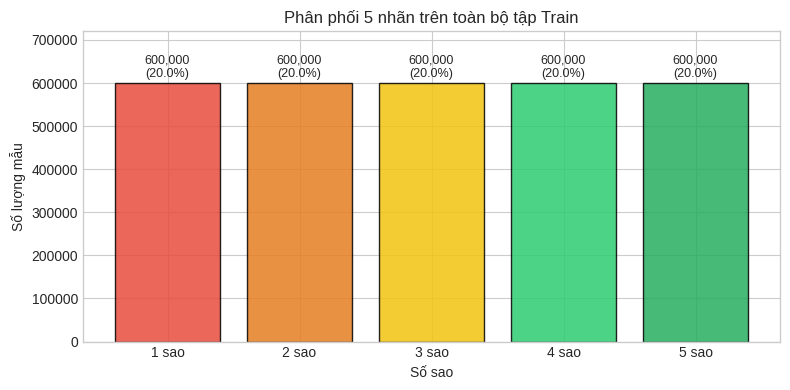

In [3]:
t0 = time.time()
train_labels = pd.read_csv(TRAIN_CSV, usecols=['class_index'], engine='pyarrow')['class_index']
test_labels  = pd.read_csv(TEST_CSV,  usecols=['class_index'], engine='pyarrow')['class_index']
N_TRAIN_FULL, N_TEST_FULL = len(train_labels), len(test_labels)

dist = pd.DataFrame({'Train': train_labels.value_counts().sort_index(),
                     'Test':  test_labels.value_counts().sort_index()})
dist['Train (%)'] = (dist['Train'] / N_TRAIN_FULL * 100).round(2)
dist['Test (%)']  = (dist['Test']  / N_TEST_FULL  * 100).round(2)
print(f'Tổng số dòng: train = {N_TRAIN_FULL:,} | test = {N_TEST_FULL:,}  (đọc trong {time.time()-t0:.1f}s)')
display(dist)

plt.figure(figsize=(8, 4))
colors = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#27ae60']
bars = plt.bar([f'{i} sao' for i in dist.index], dist['Train'].values, color=colors, edgecolor='black', alpha=0.85)
plt.ylim(0, dist['Train'].max() * 1.2)
for bar, pct in zip(bars, dist['Train (%)']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.01,
             f'{int(bar.get_height()):,}\n({pct}%)', ha='center', va='bottom', fontsize=9)
plt.title('Phân phối 5 nhãn trên toàn bộ tập Train')
plt.xlabel('Số sao'); plt.ylabel('Số lượng mẫu')
plt.show()

del train_labels, test_labels

**Nhận xét:** dữ liệu **cân bằng hoàn hảo**: mỗi nhãn có đúng 600.000 mẫu ở tập train (20,00%) và 130.000 mẫu ở tập test (20,00%), nên biểu đồ cột có 5 cột cao bằng nhau.

## 3. Kiểm tra giá trị khuyết thiếu (Missing Values)

In [4]:
t0 = time.time()
rows = []
for split, path in [('Train', TRAIN_CSV), ('Test', TEST_CSV)]:
    for col in ['class_index', 'review_title', 'review_text']:
        s = pd.read_csv(path, usecols=[col], engine='pyarrow')[col]
        miss = int(s.isna().sum())
        rows.append({'Tập': split, 'Cột': col, 'Số dòng': len(s),
                     'Missing': miss, 'Tỉ lệ (%)': round(miss / len(s) * 100, 4)})
        del s
df_missing = pd.DataFrame(rows)
print(f'Kiểm tra xong trong {time.time()-t0:.1f}s')
display(df_missing)

Kiểm tra xong trong 16.0s


,Tập,Cột,Số dòng,Missing,Tỉ lệ (%)
0,Train,class_index,3000000,0,0.0000
1,Train,review_title,3000000,188,0.0063
2,Train,review_text,3000000,0,0.0000
3,Test,class_index,650000,0,0.0000
4,Test,review_title,650000,26,0.0040
5,Test,review_text,650000,0,0.0000


**Cách xử lý:** các ô trống ở review_title và review_text được thay bằng chuỗi rỗng. Nếu tỉ lệ thiếu rất nhỏ thì cách xử lý này không ảnh hưởng đáng kể tới kết quả.

## 4. Lấy mẫu dữ liệu và kiểm tra cân bằng nhãn

Dữ liệu train có 3 triệu dòng. Notebook lấy SAMPLE_SIZE dòng đầu (mặc định 600.000, trên mức 500.000 yêu cầu) và TEST_SAMPLE_SIZE dòng đầu của test.

In [5]:
t0 = time.time()
df_train = pd.read_csv(TRAIN_CSV, nrows=SAMPLE_SIZE)
df_test  = pd.read_csv(TEST_CSV,  nrows=TEST_SAMPLE_SIZE)

# Xử lý missing values
for d in (df_train, df_test):
    d['review_title'] = d['review_title'].fillna('').astype(str)
    d['review_text']  = d['review_text'].fillna('').astype(str)

def make_balanced(df, name, tol=1.05):
    counts = df['class_index'].value_counts().sort_index()
    ratio = counts.max() / counts.min()
    print(f'[{name}] số mẫu mỗi nhãn: {counts.to_dict()} | tỉ lệ max/min = {ratio:.3f}')
    if ratio > tol:
        n = counts.min()
        df = df.groupby('class_index', group_keys=False).sample(n=n, random_state=RANDOM_STATE)
        print(f'[{name}] lệch quá {int((tol-1)*100)}% nên đã cân bằng, mỗi nhãn còn {n:,} mẫu.')
    else:
        print(f'[{name}] đã cân bằng, giữ nguyên.')
    return df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

df_train = make_balanced(df_train, 'Train')
df_test  = make_balanced(df_test,  'Test')

print(f'\nNạp dữ liệu hoàn tất trong {time.time()-t0:.1f}s')
print(f'Train shape: {df_train.shape} | Test shape: {df_test.shape}')
df_train.head(3)

[Train] số mẫu mỗi nhãn: {1: 116894, 2: 119692, 3: 121453, 4: 120371, 5: 121590} | tỉ lệ max/min = 1.040
[Train] đã cân bằng, giữ nguyên.
[Test] số mẫu mỗi nhãn: {1: 19500, 2: 19994, 3: 20192, 4: 19809, 5: 20505} | tỉ lệ max/min = 1.052
[Test] lệch quá 5% nên đã cân bằng, mỗi nhãn còn 19,500 mẫu.

Nạp dữ liệu hoàn tất trong 6.4s
Train shape: (600000, 3) | Test shape: (97500, 3)


,class_index,review_title,review_text
0,4,eargels saves my bluetooth,I have a jabra bluetooth that I just could not get to sit on my ear correctly. It sat in the drawer never being used with the addition of the ear gels not o...
1,4,Surprised by the quality of the writing,Being that much of these compilation was written over a hundred years ago the writing is surprisingly modern. All of my experience with Sherlock Holmes has ...
2,4,The power of free will,To me the main theme of this book is the amazing powerful drive for free will in relationships. The grace is the gift of the acknowledgement of independence...


## 5. Tiền xử lý văn bản



In [6]:
NEGATIONS = {'no', 'not', 'nor', 'never', 'nothing', 'nobody', 'none', 'neither', 'cannot', 'without'}
STOP_WORDS = sorted(ENGLISH_STOP_WORDS - NEGATIONS)
print('Các từ phủ định được giữ lại (vốn nằm trong danh sách stop words):', sorted(NEGATIONS & ENGLISH_STOP_WORDS))
print('Số stop words còn lại để loại bỏ:', len(STOP_WORDS))

def clean_series(s):
    s = s.astype(object).str.lower()                                 # dùng kiểu object để regex Python hoạt động ở mọi bản pandas
    s = s.str.replace('\\n', ' ', regex=False)                       # \n dạng chữ trong file CSV
    s = s.str.replace(r'<[^>]+>', ' ', regex=True)                   # thẻ HTML
    s = s.str.replace(r'https?://\S+|www\.\S+', ' url ', regex=True) # link
    s = s.str.replace("won't", 'will not', regex=False)
    s = s.str.replace("can't", 'can not', regex=False)
    s = s.str.replace(r"n't\b", ' not', regex=True)                  # don't, isn't, didn't...
    s = s.str.replace('!', ' exclam ', regex=False)
    s = s.str.replace('?', ' quest ', regex=False)
    s = s.str.replace(r'[^a-z0-9 ]', ' ', regex=True)                # bỏ ký tự đặc biệt
    s = s.str.replace(r'(.)\1{2,}', r'\1\1', regex=True)             # soooo -> soo
    s = s.str.replace(r'\s+', ' ', regex=True).str.strip()
    return s

t0 = time.time()
print('Đang làm sạch văn bản...')
for d in (df_train, df_test):
    d['full_raw'] = d['review_title'] + ' . ' + d['review_text']
    d['clean'] = clean_series(d['full_raw'])
print(f'Tiền xử lý hoàn tất trong {time.time()-t0:.1f}s')

len_before = df_train['full_raw'].str.len().mean()
len_after  = df_train['clean'].str.len().mean()
n_empty = int((df_train['clean'].str.len() == 0).sum())
print(f'Độ dài trung bình: {len_before:.0f} ký tự (trước) -> {len_after:.0f} ký tự (sau)')
print(f'Số review rỗng sau khi làm sạch: {n_empty}')

df_train[['full_raw', 'clean']].head(3)

Các từ phủ định được giữ lại (vốn nằm trong danh sách stop words): ['cannot', 'neither', 'never', 'no', 'nobody', 'none', 'nor', 'not', 'nothing', 'without']
Số stop words còn lại để loại bỏ: 308
Đang làm sạch văn bản...
Tiền xử lý hoàn tất trong 53.4s
Độ dài trung bình: 449 ký tự (trước) -> 442 ký tự (sau)
Số review rỗng sau khi làm sạch: 1


,full_raw,clean
0,eargels saves my bluetooth . I have a jabra bluetooth that I just could not get to sit on my ear correctly. It sat in the drawer never being used with the a...,eargels saves my bluetooth i have a jabra bluetooth that i just could not get to sit on my ear correctly it sat in the drawer never being used with the addi...
1,Surprised by the quality of the writing . Being that much of these compilation was written over a hundred years ago the writing is surprisingly modern. All ...,surprised by the quality of the writing being that much of these compilation was written over a hundred years ago the writing is surprisingly modern all of ...
2,The power of free will . To me the main theme of this book is the amazing powerful drive for free will in relationships. The grace is the gift of the acknow...,the power of free will to me the main theme of this book is the amazing powerful drive for free will in relationships the grace is the gift of the acknowled...


**Nhận xét:** bảng trên so sánh văn bản trước và sau làm sạch. Các ký tự rác (\n, thẻ HTML, ký tự đặc biệt) đã được loại bỏ, dạng viết tắt phủ định được mở rộng, còn dấu ! và ? được giữ lại dưới dạng từ để mô hình vẫn tận dụng được tín hiệu cảm xúc.

## 6. Đặc trưng hình thái và khám phá dữ liệu

Tính các đặc trưng đơn giản từ **văn bản gốc** (chưa làm sạch, vì cần giữ chữ in hoa và dấu câu): độ dài, số từ, số dấu !, số dấu ?, tỉ lệ chữ in hoa. Sau đó xem chúng thay đổi thế nào theo số sao.

Trích xuất đặc trưng xong trong 24.3s

Giá trị trung bình của từng đặc trưng theo số sao:


,char_count,word_count,avg_word_len,title_len,excl_count,quest_count,caps_ratio
class_index,,,,,,,
1,441.357,81.163,5.424,24.618,1.014,0.320,0.045
2,477.591,87.593,5.432,24.894,0.496,0.254,0.036
3,469.347,86.221,5.414,25.383,0.374,0.192,0.037
4,450.611,82.494,5.439,24.759,0.587,0.123,0.038
5,406.743,74.611,5.435,24.483,1.231,0.102,0.045


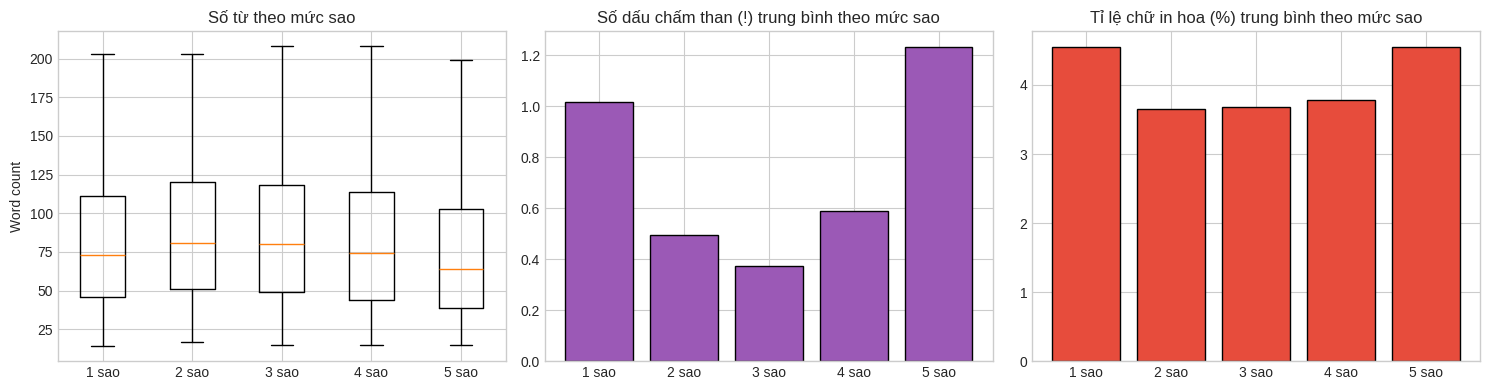

In [7]:
def extract_features(df):
    full, title = df['full_raw'], df['review_title']
    f = pd.DataFrame(index=df.index)
    f['char_count']   = full.str.len()
    f['word_count']   = full.str.count(r'\S+')
    f['avg_word_len'] = f['char_count'] / (f['word_count'] + 1e-5)
    f['title_len']    = title.str.len()
    f['excl_count']   = full.str.count('!')
    f['quest_count']  = full.str.count(r'\?')
    f['caps_ratio']   = full.str.count(r'[A-Z]') / (f['char_count'] + 1e-5)
    return f

t0 = time.time()
train_meta = extract_features(df_train)
test_meta  = extract_features(df_test)
print(f'Trích xuất đặc trưng xong trong {time.time()-t0:.1f}s')

star = df_train['class_index']
print('\nGiá trị trung bình của từng đặc trưng theo số sao:')
display(train_meta.groupby(star).mean().round(3))

# Vẽ trên mẫu 50.000 dòng cho nhanh
sub = rng.choice(len(df_train), size=min(50_000, len(df_train)), replace=False)
sub_meta, sub_star = train_meta.iloc[sub], star.iloc[sub]
star_labels = [f'{k} sao' for k in range(1, 6)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].boxplot([sub_meta.loc[sub_star == k, 'word_count'] for k in range(1, 6)], showfliers=False)
axes[0].set_xticklabels(star_labels); axes[0].set_title('Số từ theo mức sao'); axes[0].set_ylabel('Word count')

axes[1].bar(star_labels, train_meta.groupby(star)['excl_count'].mean().values, color='#9b59b6', edgecolor='black')
axes[1].set_title('Số dấu chấm than (!) trung bình theo mức sao')

axes[2].bar(star_labels, train_meta.groupby(star)['caps_ratio'].mean().values * 100, color='#e74c3c', edgecolor='black')
axes[2].set_title('Tỉ lệ chữ in hoa (%) trung bình theo mức sao')
plt.show()

Nhận xét: nhìn bảng trung bình và 3 biểu đồ:

- Số từ theo mức sao: review 2 sao dài nhất và 5 sao ngắn nhất. Thứ tự độ dài đi theo dạng chữ U ngược.
- Dấu chấm than (!): có dạng chữ U: 5 sao cao nhất, tiếp theo là 1 sao , thấp nhất ở 3 sao . Như vậy ! phản ánh cảm xúc mạnh (cả khen lẫn chê) chứ không cho biết chiều khen hay chê.
- Tỉ lệ chữ in hoa: cũng dạng chữ U, 1 sao và 5 sao cùng cao nhất (khoảng 4,5%), các mức giữa chỉ khoảng 3,6–3,8%.

## 7. Vector hóa văn bản bằng TF-IDF (unigram + bigram)

Máy tính không hiểu chữ nên văn bản được đổi thành vector số bằng TF-IDF . Dùng cả từ đơn và cụm hai từ (not good, waste money).



In [8]:
y_train = df_train['class_index'].values
y_test  = df_test['class_index'].values

t0 = time.time()
print('Bước 1/2: xây từ vựng...')
tfidf_vocab = TfidfVectorizer(max_features=TFIDF_FEATURES, ngram_range=(1, 2), min_df=3,
                              sublinear_tf=True, stop_words=STOP_WORDS)
tfidf_vocab.fit(df_train['clean'].iloc[:VOCAB_FIT_SIZE])

print('Bước 2/2: vector hóa toàn bộ train và test...')
tfidf = TfidfVectorizer(vocabulary=tfidf_vocab.vocabulary_, ngram_range=(1, 2),
                        sublinear_tf=True, stop_words=STOP_WORDS)
X_train = tfidf.fit_transform(df_train['clean'])
X_test  = tfidf.transform(df_test['clean'])
vocab = np.array(tfidf.get_feature_names_out())

print(f'TF-IDF hoàn tất trong {time.time()-t0:.1f}s')
print(f'Train sparse matrix: {X_train.shape} | Test sparse matrix: {X_test.shape}')
print(f'Bộ nhớ ma trận train: {(X_train.data.nbytes + X_train.indices.nbytes)/1e6:.0f} MB')
print('Ví dụ 15 từ/cụm từ trong từ vựng:', list(vocab[:15]))

Bước 1/2: xây từ vựng...
Bước 2/2: vector hóa toàn bộ train và test...
TF-IDF hoàn tất trong 109.8s
Train sparse matrix: (600000, 50000) | Test sparse matrix: (97500, 50000)
Bộ nhớ ma trận train: 294 MB
Ví dụ 15 từ/cụm từ trong từ vựng: ['00', '00 00', '00 exclam', '00 not', '00 shipping', '00 times', '00 years', '007', '01', '02', '03', '04', '05', '06', '07']


## 8. Khai phá dữ liệu 1: chủ đề ẩn (LSA) và phân cụm (KMeans)

**LSA (TruncatedSVD)** nén ma trận TF-IDF xuống 100 chiều, mỗi chiều là một "chủ đề ngữ nghĩa" gồm các từ hay đi cùng nhau. **KMeans** sau đó gom các review có nội dung gần nhau thành cụm, **không dùng nhãn số sao**. Sau khi gom, ta mới đối chiếu cụm với số sao để xem cụm nào gồm toàn review tiêu cực, cụm nào toàn tích cực.

LSA 100 chiều xong trong 16.2s | phương sai giải thích được: 7.7%


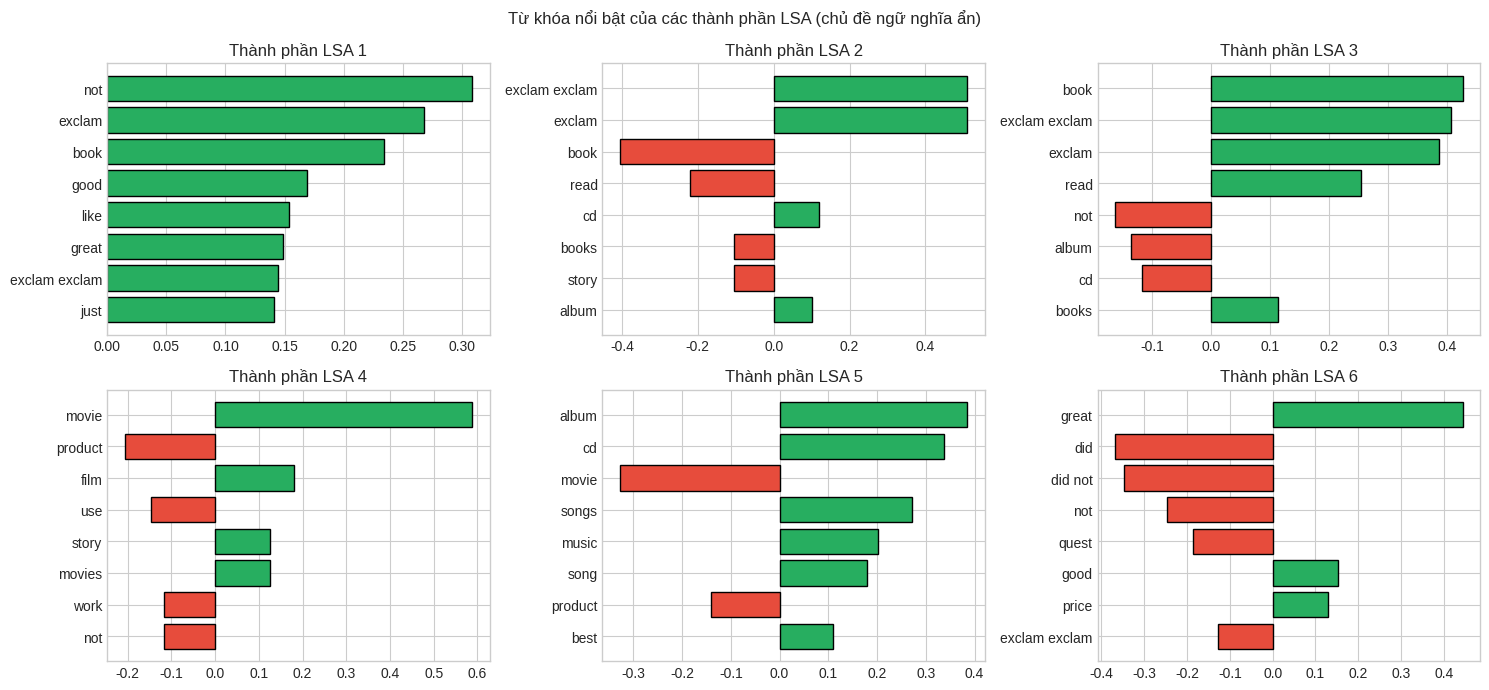

In [9]:
t0 = time.time()
idx_cl = rng.choice(X_train.shape[0], size=min(CLUSTER_SIZE, X_train.shape[0]), replace=False)
Xc, yc = X_train[idx_cl], y_train[idx_cl]

n_comp = min(100, Xc.shape[1] - 1)
svd = TruncatedSVD(n_components=n_comp, random_state=RANDOM_STATE)
Z = svd.fit_transform(Xc)
Zn = normalize(Z)    # chuẩn hóa độ dài vector để KMeans đo theo hướng (gần với cosine)
print(f'LSA {n_comp} chiều xong trong {time.time()-t0:.1f}s | phương sai giải thích được: {svd.explained_variance_ratio_.sum()*100:.1f}%')

# Từ khóa của 6 thành phần LSA đầu tiên (màu xanh: trọng số dương, đỏ: trọng số âm)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, ax in enumerate(axes.ravel()):
    comp = svd.components_[i]
    order = np.argsort(-np.abs(comp))[:8]
    ax.barh(vocab[order][::-1], comp[order][::-1],
            color=['#27ae60' if w > 0 else '#e74c3c' for w in comp[order][::-1]], edgecolor='black')
    ax.set_title(f'Thành phần LSA {i+1}')
plt.suptitle('Từ khóa nổi bật của các thành phần LSA (chủ đề ngữ nghĩa ẩn)')
plt.show()

**Nhận xét:** LSA nén TF-IDF xuống 100 chiều nhưng chỉ giữ được 7,7% phương sai, mức thấp do ma trận từ vựng rất thưa và đa dạng. Các từ cùng màu đi cùng nhau, khác màu đối lập nhau. Ta có 6 thành phần:

- Thành phần 1: toàn trọng số dương với các từ chung nhất (not, exclam, book, good, like, great), là từ vựng phổ biến của mọi review, chưa tách thành chủ đề rõ ràng.
- Thành phần 2: exclam, exclam exclam đối lập với book, read, nên là trục "cảm thán" so với "nói về sách".
- Thành phần 3: nhóm sách (book, read, books, kèm exclam) đối lập với album, cd, not.
- Thành phần 4: nhóm phim (movie, film, movies, story) đối lập với sản phẩm dùng được (product, use, work).
- Thành phần 5: nhóm âm nhạc (album, cd, songs, music, song) đối lập với movie, product.
- Thành phần 6: thiên về sắc thái: great, good, price (khen, nói về giá) đối lập với did, did not, not, quest (phàn nàn, thắc mắc).

k =  4 | silhouette = 0.0409
k =  6 | silhouette = 0.0480
k =  8 | silhouette = 0.0309
k = 10 | silhouette = 0.0376

=> Chọn k = 6 (silhouette cao nhất)


,Cụm,Số review,Tỉ lệ (%),Số sao TB,Nhãn chiếm nhiều nhất,Từ khóa nổi bật
0,0,23447,23.4,2.82,1,"not, good, like, did, great, product, just, dvd"
1,4,14910,14.9,2.85,1,"use, not, product, works, does, great, work, used"
2,1,13143,13.1,2.96,3,"movie, film, not, good, movies, exclam, watch, great"
3,2,27113,27.1,3.10,4,"book, read, not, books, story, reading, good, like"
4,5,12493,12.5,3.27,5,"album, cd, songs, music, not, song, like, good"
5,3,8894,8.9,3.28,5,"exclam, exclam exclam, not, great, love, book, quest, just"


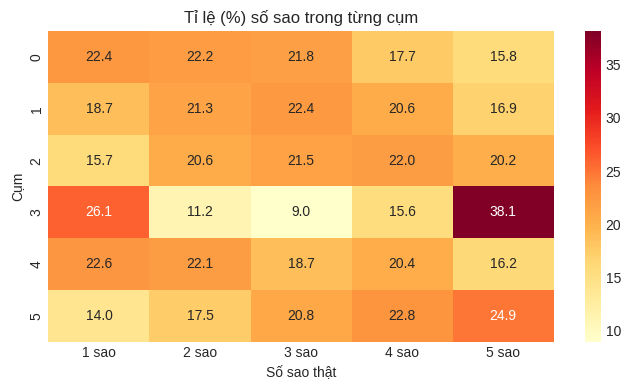

In [10]:
# Chọn số cụm k bằng hệ số silhouette trên mẫu 10.000 review
sil_idx = rng.choice(len(Zn), size=min(10_000, len(Zn)), replace=False)
sil_results = {}
for k in [4, 6, 8, 10]:
    km = MiniBatchKMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=3, batch_size=4096).fit(Zn)
    sil_results[k] = silhouette_score(Zn[sil_idx], km.labels_[sil_idx])
    print(f'k = {k:2d} | silhouette = {sil_results[k]:.4f}')

best_k = max(sil_results, key=sil_results.get)
km_best = MiniBatchKMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=3, batch_size=4096).fit(Zn)
cluster_labels = km_best.labels_
print(f'\n=> Chọn k = {best_k} (silhouette cao nhất)')

# Hồ sơ từng cụm
profiles = []
for c in range(best_k):
    mask = cluster_labels == c
    mean_tfidf = np.asarray(Xc[mask].mean(axis=0)).ravel()
    star_counts = np.bincount(yc[mask], minlength=6)[1:]
    profiles.append({
        'Cụm': c,
        'Số review': int(mask.sum()),
        'Tỉ lệ (%)': round(mask.mean() * 100, 1),
        'Số sao TB': round(yc[mask].mean(), 2),
        'Nhãn chiếm nhiều nhất': int(star_counts.argmax() + 1),
        'Từ khóa nổi bật': ', '.join(vocab[np.argsort(-mean_tfidf)[:8]]),
    })
df_cluster = pd.DataFrame(profiles).sort_values('Số sao TB').reset_index(drop=True)
display(df_cluster)

# Đối chiếu cụm với số sao (tỉ lệ % theo từng cụm)
ct = pd.crosstab(cluster_labels, yc, normalize='index') * 100
plt.figure(figsize=(7, 4))
sns.heatmap(ct, annot=True, fmt='.1f', cmap='YlOrRd', xticklabels=[f'{k} sao' for k in ct.columns])
plt.title('Tỉ lệ (%) số sao trong từng cụm'); plt.xlabel('Số sao thật'); plt.ylabel('Cụm')
plt.show()

**Nhận xét:**

- **Chọn k:** chọn k = 6 với  silhouette = 0.0480. Tuy nhiên cả 4 giá trị đều dưới 0,05 (rất gần 0) và chênh nhau rất ít, nghĩa là các cụm chồng lấn mạnh và ranh giới giữa cụm không rõ.
- **Hồ sơ cụm:** các cụm tách chủ yếu theo chủ đề sản phẩm. **Cụm 2** (27,1%) là sách; **cụm 0** (23,4%) là cụm từ chung ; **cụm 4** (14,9%) là sản phẩm dùng được; **cụm 1** (13,1%) là phim; **cụm 5** (12,5%) là âm nhạc; **cụm 3** (8,9%) là cụm cảm thán .
- **Số sao trung bình** của các cụm chỉ dao động trong khoảng hẹp 2,82 đến 3,28, quanh mức 3 sao. Vì vậy không có cụm nào gồm toàn review tiêu cực hoặc toàn tích cực, và chênh lệch giữa cụm "thấp nhất" (cụm 0) với cụm "cao nhất" (cụm 3) không lớn.
- **Heatmap:** cụm 3 là ngoại lệ rõ nhất, có 38,1% là 5 sao và 26,1% là 1 sao, trong khi 2, 3, 4 sao chỉ chiếm 11,2%, 9,0% và 15,6%. Đây là cụm của các review cảm xúc mạnh ở hai cực. Cụm 5 (âm nhạc) nghiêng nhẹ về tích cực (5 sao 24,9% so với 1 sao 14,0%), cụm 0 nghiêng nhẹ về tiêu cực (1 sao 22,4% so với 5 sao 15,8%), các cụm còn lại phân bố khá đều giữa 5 mức sao.

## 9. Khai phá dữ liệu 2: cụm từ nổi bật và luật kết hợp (từ khóa → số sao)

Mỗi review được xem là một "giỏ hàng" gồm các từ/cụm từ xuất hiện trong đó, cộng với một "mặt hàng" là số sao. Luật kết hợp dạng **{từ khóa} → {k sao}** được đo bằng ba chỉ số:

- **Support** của luật: tỉ lệ review chứa từ khóa *và* có đúng k sao.
- **Confidence**: trong các review chứa từ khóa, bao nhiêu phần trăm có k sao, tức xác suất P(k sao | từ khóa).
- **Lift** = confidence / P(k sao). Lift > 1 nghĩa là từ khóa làm tăng khả năng review thuộc k sao so với ngẫu nhiên.

In [11]:
t0 = time.time()
B = X_train.copy()
B.data = np.ones_like(B.data)                 # nhị phân: từ/cụm từ có xuất hiện trong review hay không
N = B.shape[0]
Y = np.zeros((N, 5), dtype=np.float32)
Y[np.arange(N), y_train - 1] = 1              # one-hot số sao

doc_freq = np.asarray(B.sum(axis=0)).ravel()  # số review chứa từng từ khóa
co = np.asarray(B.T.dot(Y))                   # số review chứa từ khóa VÀ có k sao (n_features x 5)
prior = np.bincount(y_train, minlength=6)[1:] / N
support_term = doc_freq / N

idx = np.where(support_term >= MIN_SUPPORT)[0]
rules_df = pd.DataFrame({
    'term':         np.repeat(vocab[idx], 5),
    'consequent':   np.tile(np.arange(1, 6), len(idx)),
    'support_term': np.repeat(support_term[idx], 5),
    'support_rule': (co[idx] / N).ravel(),
    'confidence':   (co[idx] / doc_freq[idx, None]).ravel(),
})
rules_df['lift'] = rules_df['confidence'] / prior[rules_df['consequent'].values - 1]
rules_df['is_bigram'] = rules_df['term'].str.contains(' ')
print(f'Đã tính {len(rules_df):,} luật từ {len(idx):,} từ khóa đạt ngưỡng support ({time.time()-t0:.1f}s)')

def top_rules(star_k, n=8, only_bigram=False):
    r = rules_df[rules_df['consequent'] == star_k]
    if only_bigram:
        r = r[r['is_bigram']]
    return (r.sort_values('lift', ascending=False).head(n)
             [['term', 'support_term', 'support_rule', 'confidence', 'lift']]
             .rename(columns={'term': 'Từ khóa (vế trái)'}).round(4).reset_index(drop=True))

for k in [1, 5]:
    print(f'\n=== Top luật: {{từ khóa}} -> {{{k} sao}} (xếp theo lift) ===')
    display(top_rules(k, n=10))

Đã tính 27,575 luật từ 5,515 từ khóa đạt ngưỡng support (0.7s)

=== Top luật: {từ khóa} -> {1 sao} (xếp theo lift) ===


,Từ khóa (vế trái),support_term,support_rule,confidence,lift
0,zero stars,0.0014,0.0013,0.9370,4.8097
1,worst movies,0.0011,0.0009,0.8738,4.4853
2,piece junk,0.0021,0.0018,0.8650,4.4400
3,worst movie,0.0018,0.0015,0.8294,4.2570
4,total waste,0.0015,0.0012,0.7713,3.9590
5,worst book,0.0016,0.0012,0.7700,3.9524
6,complete waste,0.0015,0.0012,0.7667,3.9356
7,horrible exclam,0.0014,0.0010,0.7610,3.9063
8,awful exclam,0.0011,0.0008,0.7596,3.8991
9,junk,0.0071,0.0053,0.7361,3.7783



=== Top luật: {từ khóa} -> {5 sao} (xếp theo lift) ===


,Từ khóa (vế trái),support_term,support_rule,confidence,lift
0,excellent exclam,0.0014,0.0011,0.7444,3.6734
1,fantastic exclam,0.0011,0.0008,0.7216,3.5611
2,exclam highly,0.0014,0.0010,0.7190,3.5482
3,amazing exclam,0.0017,0.0012,0.7137,3.5220
4,wonderful exclam,0.0013,0.0009,0.6992,3.4504
5,awesome exclam,0.0026,0.0018,0.6965,3.4368
6,exclam best,0.0022,0.0015,0.6839,3.3748
7,best exclam,0.0029,0.0020,0.6691,3.3019
8,love exclam,0.0053,0.0035,0.6636,3.2747
9,best books,0.0021,0.0014,0.6568,3.2408


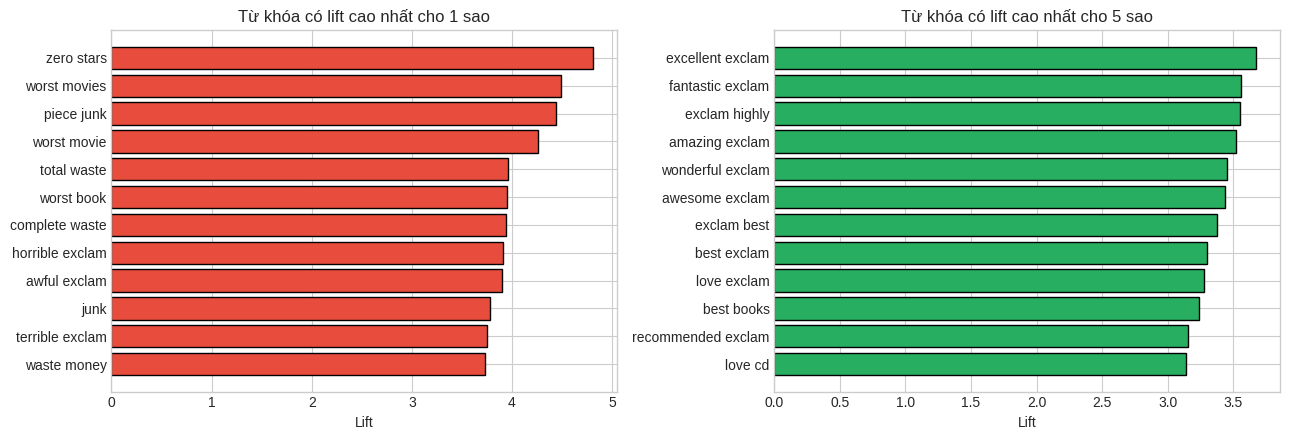


=== Top cụm hai từ liên quan nhất tới 1 sao ===


,Từ khóa (vế trái),support_term,support_rule,confidence,lift
0,zero stars,0.0014,0.0013,0.9370,4.8097
1,worst movies,0.0011,0.0009,0.8738,4.4853
2,piece junk,0.0021,0.0018,0.8650,4.4400
3,worst movie,0.0018,0.0015,0.8294,4.2570
4,total waste,0.0015,0.0012,0.7713,3.9590
5,worst book,0.0016,0.0012,0.7700,3.9524
6,complete waste,0.0015,0.0012,0.7667,3.9356
7,horrible exclam,0.0014,0.0010,0.7610,3.9063
8,awful exclam,0.0011,0.0008,0.7596,3.8991
9,terrible exclam,0.0011,0.0008,0.7311,3.7524



=== Top cụm hai từ liên quan nhất tới 5 sao ===


,Từ khóa (vế trái),support_term,support_rule,confidence,lift
0,excellent exclam,0.0014,0.0011,0.7444,3.6734
1,fantastic exclam,0.0011,0.0008,0.7216,3.5611
2,exclam highly,0.0014,0.0010,0.7190,3.5482
3,amazing exclam,0.0017,0.0012,0.7137,3.5220
4,wonderful exclam,0.0013,0.0009,0.6992,3.4504
5,awesome exclam,0.0026,0.0018,0.6965,3.4368
6,exclam best,0.0022,0.0015,0.6839,3.3748
7,best exclam,0.0029,0.0020,0.6691,3.3019
8,love exclam,0.0053,0.0035,0.6636,3.2747
9,best books,0.0021,0.0014,0.6568,3.2408


In [12]:
# Biểu đồ lift của các từ khóa mạnh nhất cho 1 sao và 5 sao
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, k, col in zip(axes, [1, 5], ['#e74c3c', '#27ae60']):
    r = top_rules(k, n=12)
    ax.barh(r['Từ khóa (vế trái)'][::-1], r['lift'][::-1], color=col, edgecolor='black')
    ax.set_title(f'Từ khóa có lift cao nhất cho {k} sao'); ax.set_xlabel('Lift')
plt.show()

# Cụm hai từ nổi bật (phân tích cụm từ)
for k in [1, 5]:
    print(f'\n=== Top cụm hai từ liên quan nhất tới {k} sao ===')
    display(top_rules(k, n=10, only_bigram=True))

In [13]:
# Vai trò của từ phủ định: cụm bắt đầu bằng "not", "no", "never"... đi cùng số sao nào?
neg_terms = rules_df[rules_df['is_bigram'] & rules_df['term'].str.split().str[0].isin(NEGATIONS)]
if len(neg_terms):
    neg_conf = neg_terms.pivot(index='term', columns='consequent', values='confidence') * 100
    neg_conf.columns = [f'{c} sao (%)' for c in neg_conf.columns]
    neg_conf['support (%)'] = neg_terms.drop_duplicates('term').set_index('term')['support_term'] * 100
    print('Các cụm phủ định phổ biến nhất và phân bố số sao đi kèm (confidence, %):')
    display(neg_conf.sort_values('support (%)', ascending=False).head(12).round(2))
else:
    print('Không có cụm phủ định nào đạt ngưỡng support. Thử giảm MIN_SUPPORT.')

del B, Y

Các cụm phủ định phổ biến nhất và phân bố số sao đi kèm (confidence, %):


,1 sao (%),2 sao (%),3 sao (%),4 sao (%),5 sao (%),support (%)
term,,,,,,
not good,20.29,34.99,28.80,11.86,4.07,2.77
not like,18.52,28.19,22.75,18.02,12.52,2.39
not know,23.62,23.12,20.78,17.15,15.33,2.38
not buy,57.97,23.62,10.90,4.15,3.35,2.22
not work,46.72,28.29,15.18,6.33,3.48,1.93
not really,12.51,28.51,33.38,17.10,8.50,1.83
not bad,7.17,19.32,49.30,18.91,5.29,1.74
not worth,46.44,37.94,12.17,2.28,1.17,1.55
not think,19.93,25.27,25.80,16.00,13.00,1.48


**Nhận xét:** có 27.575 luật được tính từ 5.515 từ khóa đạt ngưỡng support 0,1%.

- **Luật cho 1 sao:** các luật mạnh nhất là cụm chê rất nặng: zero stars (confidence 93,7%, lift 4,81), worst movies (lift 4,49), piece junk (86,5%, lift 4,44), worst movie, total waste, worst book, complete waste. Lift cao nhất 4,81 đã gần mức tối đa. Từ đơn junk là từ đơn duy nhất lọt top 10 (lift 3,78, confidence 73,6%) và cũng phổ biến nhất (support 0,71%).
- **Luật cho 5 sao:** lift thấp hơn 1 sao (cao nhất 3,67), và 9 trong 10 cụm đều chứa exclam: excellent exclam (74,4%, lift 3,67), fantastic exclam, amazing exclam, awesome exclam, best exclam, love exclam... Tức là từ khen đi kèm dấu ! mới là tín hiệu mạnh cho 5 sao; chỉ có best books là cụm không chứa exclam. Dấu ! cũng xuất hiện ở các cụm 1 sao (horrible exclam, awful exclam, terrible exclam).
- **Support rất nhỏ:** các luật này chính xác cao nhưng hiếm, mỗi luật chỉ phủ một phần rất nhỏ dữ liệu.
- **Cụm hai từ:** bảng bigram cho 5 sao giống hệt bảng tổng vì mọi luật top đều là bigram; ở 1 sao chỉ khác ở chỗ junk được thay bằng terrible exclam.

**Cụm phủ định:** phủ định không đơn giản dồn về mức sao thấp, ý nghĩa phụ thuộc vào từ đi sau:

- Phủ định gắn với hành vi tiêu cực thì nghiêng hẳn về 1 sao: not waste (71,5% là 1 sao), not buy (58,0%), not work (46,7%), not worth (84,4% ở 1–2 sao), not recommend (79,7% ở 1–2 sao).
- not good tập trung ở 2 sao (35,0%) và 3 sao (28,8%), chỉ 20,3% là 1 sao. not great (44,6%), not bad (49,3%) và not really (33,4%) đều tập trung ở 3 sao; not bad chỉ có 7,2% là 1 sao.
- not like, not know, not think phân bố khá đều ở cả 5 mức (confidence mỗi mức khoảng 12–28%) nên gần như không giúp phân biệt

## 10. Tinh chỉnh tham số và huấn luyện 3 mô hình

Ba mô hình, cùng dùng đặc trưng TF-IDF để so sánh:

1. Complement Naive Bayes
2. SGD Logistic Regression
3. SGD Linear SVM

**Tinh chỉnh tham số:** lấy TUNE_SIZE review từ tập train, chia 80% huấn luyện và 20% kiểm định (có phân tầng theo nhãn). Thử nhiều giá trị alpha (cường độ điều chuẩn) cho từng mô hình, chọn giá trị có **macro F1 trên tập kiểm định** cao nhất. **Tập test không được dùng để chọn tham số.** Với SGD, max_iter được nâng lên MAX_ITER và ghi lại số vòng thực tế (n_iter) cùng việc mô hình có hội tụ hay không.

Tinh chỉnh trên 120,000 mẫu huấn luyện / 30,000 mẫu kiểm định
Tinh chỉnh xong trong 43.4s


,Mô hình,alpha,Val Accuracy,Val Macro F1,n_iter,Hội tụ
0,Complement Naive Bayes,0.05,0.4825,0.4637,NaN,True
1,Complement Naive Bayes,0.1,0.4833,0.4646,NaN,True
2,Complement Naive Bayes,0.3,0.4853,0.4663,NaN,True
3,Complement Naive Bayes,0.5,0.4873,0.4683,NaN,True
4,Complement Naive Bayes,1,0.4891,0.4700,NaN,True
5,SGD Logistic Regression,1e-06,0.4929,0.4919,22.0,True
6,SGD Logistic Regression,3e-06,0.5167,0.5133,16.0,True
7,SGD Logistic Regression,1e-05,0.5292,0.5244,12.0,True
8,SGD Logistic Regression,3e-05,0.5266,0.5206,9.0,True
9,SGD Logistic Regression,0.0001,0.5127,0.5055,8.0,True



THAM SỐ TỐT NHẤT (theo macro F1 trên tập kiểm định):


,alpha,Val Accuracy,Val Macro F1,n_iter,Hội tụ
Mô hình,,,,,
Complement Naive Bayes,1,0.4891,0.4700,NaN,True
SGD Linear SVM,1e-05,0.5106,0.4990,18.0,True
SGD Logistic Regression,1e-05,0.5292,0.5244,12.0,True


Lưu ý: Complement Naive Bayes có alpha tốt nhất (1) nằm ở rìa lưới tìm kiếm, nên mở rộng lưới rồi chạy lại.


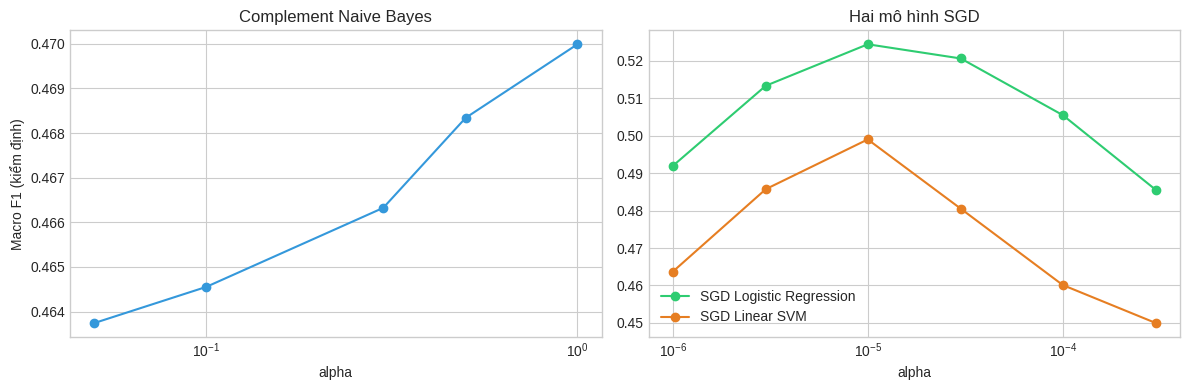

In [14]:
def fit_sgd(loss, alpha, X, y):
    model = SGDClassifier(loss=loss, penalty='l2', alpha=alpha, max_iter=MAX_ITER, tol=1e-3,
                          random_state=RANDOM_STATE, n_jobs=-1)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always', ConvergenceWarning)
        model.fit(X, y)
    converged = not any(issubclass(x.category, ConvergenceWarning) for x in w)
    return model, converged

# Tập tinh chỉnh: lấy mẫu từ train rồi chia train/validation
tune_idx = rng.choice(X_train.shape[0], size=min(TUNE_SIZE, X_train.shape[0]), replace=False)
X_tune, y_tune = X_train[tune_idx], y_train[tune_idx]
X_tr, X_val, y_tr, y_val = train_test_split(X_tune, y_tune, test_size=0.2, stratify=y_tune, random_state=RANDOM_STATE)
print(f'Tinh chỉnh trên {X_tr.shape[0]:,} mẫu huấn luyện / {X_val.shape[0]:,} mẫu kiểm định')

NB_ALPHAS  = [0.05, 0.1, 0.3, 0.5, 1.0]
SGD_ALPHAS = [1e-6, 3e-6, 1e-5, 3e-5, 1e-4, 3e-4]
records = []
t0 = time.time()

for a in NB_ALPHAS:
    m = ComplementNB(alpha=a).fit(X_tr, y_tr)
    p = m.predict(X_val)
    records.append({'Mô hình': 'Complement Naive Bayes', 'alpha': a,
                    'Val Accuracy': accuracy_score(y_val, p), 'Val Macro F1': f1_score(y_val, p, average='macro'),
                    'n_iter': np.nan, 'Hội tụ': True})

for name, loss in [('SGD Logistic Regression', 'log_loss'), ('SGD Linear SVM', 'hinge')]:
    for a in SGD_ALPHAS:
        m, ok = fit_sgd(loss, a, X_tr, y_tr)
        p = m.predict(X_val)
        records.append({'Mô hình': name, 'alpha': a,
                        'Val Accuracy': accuracy_score(y_val, p), 'Val Macro F1': f1_score(y_val, p, average='macro'),
                        'n_iter': int(m.n_iter_), 'Hội tụ': ok})

df_tune = pd.DataFrame(records)
print(f'Tinh chỉnh xong trong {time.time()-t0:.1f}s')
def fmt_alpha(d):
    d = d.copy()
    d['alpha'] = d['alpha'].map(lambda a: f'{a:g}')     # hiển thị 1e-06, 3e-05... thay vì làm tròn về 0
    return d
display(fmt_alpha(df_tune).round(4))

best_idx = df_tune.groupby('Mô hình')['Val Macro F1'].idxmax()
best_params = df_tune.loc[best_idx].set_index('Mô hình')
print('\nTHAM SỐ TỐT NHẤT (theo macro F1 trên tập kiểm định):')
display(fmt_alpha(best_params[['alpha', 'Val Accuracy', 'Val Macro F1', 'n_iter', 'Hội tụ']]).round(4))

# Cảnh báo nếu giá trị tốt nhất nằm ở rìa lưới tìm kiếm (khi đó giá trị tối ưu thật có thể nằm ngoài lưới)
for name in best_params.index:
    grid = NB_ALPHAS if name == 'Complement Naive Bayes' else SGD_ALPHAS
    a = best_params.loc[name, 'alpha']
    if a in (min(grid), max(grid)):
        print(f'Lưu ý: {name} có alpha tốt nhất ({a:g}) nằm ở rìa lưới tìm kiếm, nên mở rộng lưới rồi chạy lại.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
d = df_tune[df_tune['Mô hình'] == 'Complement Naive Bayes']
axes[0].plot(d['alpha'], d['Val Macro F1'], 'o-', color='#3498db'); axes[0].set_xscale('log')
axes[0].set_title('Complement Naive Bayes'); axes[0].set_xlabel('alpha'); axes[0].set_ylabel('Macro F1 (kiểm định)')
for name, col in [('SGD Logistic Regression', '#2ecc71'), ('SGD Linear SVM', '#e67e22')]:
    d = df_tune[df_tune['Mô hình'] == name]
    axes[1].plot(d['alpha'], d['Val Macro F1'], 'o-', color=col, label=name)
axes[1].set_xscale('log'); axes[1].set_title('Hai mô hình SGD'); axes[1].set_xlabel('alpha'); axes[1].legend()
plt.show()

**Kết quả:** tinh chỉnh trên 120.000 mẫu huấn luyện / 30.000 mẫu kiểm định, chọn theo macro F1:

- **Complement Naive Bayes:** macro F1 tăng đều khi alpha tăng, từ 0,4637 (alpha = 0,05) lên 0,4700 (alpha = 1), và giá trị tốt nhất nằm ở **rìa lưới**. Mức chênh giữa các alpha rất nhỏ (khoảng 0,006), nên mô hình này ít nhạy với alpha, nhưng vì chưa thấy đỉnh nên có thể mở rộng lưới (alpha > 1) để kiểm tra.
- **SGD Logistic Regression:** đường cong có **một đỉnh rõ rệt** tại alpha = 1e-5 (macro F1 0,5244, accuracy 0,5292). Alpha nhỏ hơn (1e-6: 0,4919) hay lớn hơn (3e-4: 0,4855) đều kém đi.
- **SGD Linear SVM:** cũng có đỉnh tại alpha = 1e-5 (macro F1 0,4990, accuracy 0,5106) rồi giảm mạnh xuống 0,4500 ở alpha = 3e-4. Khoảng cách giữa accuracy và macro F1 doãn ra khi alpha lớn (ví dụ 0,4873 so với 0,4500 ở 3e-4).
- Hiện tượng "quá nhỏ thì overfit, quá lớn thì quá đơn giản" thể hiện rõ ở **hai mô hình SGD** (đường cong hình chuông); với Naive Bayes thì chưa thấy rõ.
- **Hội tụ:** cả 12 cấu hình SGD đều báo `True`. Số vòng lặp giảm khi alpha tăng (LR từ 22 xuống 7, SVM từ 44 xuống 8), và không cấu hình nào chạm MAX_ITER = 100, nên không cần tăng MAX_ITER.
- **Tham số chọn:** Naive Bayes alpha = 1, Logistic Regression alpha = 1e-5, Linear SVM alpha = 1e-5.

In [15]:
# Huấn luyện lại 3 mô hình với tham số tốt nhất trên TOÀN BỘ tập train mẫu, rồi đánh giá trên tập test
final_models, train_times, final_converged = {}, {}, {}

t0 = time.time()
final_models['Complement Naive Bayes'] = ComplementNB(alpha=best_params.loc['Complement Naive Bayes', 'alpha']).fit(X_train, y_train)
train_times['Complement Naive Bayes'] = time.time() - t0

for name, loss in [('SGD Logistic Regression', 'log_loss'), ('SGD Linear SVM', 'hinge')]:
    t0 = time.time()
    final_models[name], final_converged[name] = fit_sgd(loss, best_params.loc[name, 'alpha'], X_train, y_train)
    train_times[name] = time.time() - t0

for name, t in train_times.items():
    extra = '' if name not in final_converged else f" | hội tụ: {final_converged[name]}"
    print(f'{name:28s} | alpha = {best_params.loc[name, "alpha"]:<8g} | thời gian huấn luyện: {t:6.1f}s{extra}')

Complement Naive Bayes       | alpha = 1        | thời gian huấn luyện:    0.3s
SGD Logistic Regression      | alpha = 1e-05    | thời gian huấn luyện:   12.3s | hội tụ: True
SGD Linear SVM               | alpha = 1e-05    | thời gian huấn luyện:   11.7s | hội tụ: True


## 11. Đánh giá mô hình trên tập test

Các thước đo:

- **Accuracy**: tỉ lệ đoán đúng đúng số sao.
- **Macro F1**: trung bình F1 của 5 nhãn, mỗi nhãn có trọng số như nhau.
- **Off-by-one**: tỉ lệ đoán sai tối đa 1 sao (chấp nhận được trong thực tế).
- **MAE**: sai số tuyệt đối trung bình tính theo số sao (càng thấp càng tốt).

=== BẢNG SO SÁNH 3 MÔ HÌNH TRÊN TẬP TEST ===


,Mô hình,Accuracy (%),Precision (%),Recall (%),Macro F1 (%),Off-by-one (%),MAE (sao),Train (s),Predict (s)
0,Complement Naive Bayes,50.256,49.380,50.256,47.985,84.259,0.738,0.298,0.065
1,SGD Logistic Regression,54.478,53.637,54.478,53.800,89.137,0.612,12.328,0.061
2,SGD Linear SVM,52.104,50.528,52.104,49.266,86.829,0.667,11.748,0.063


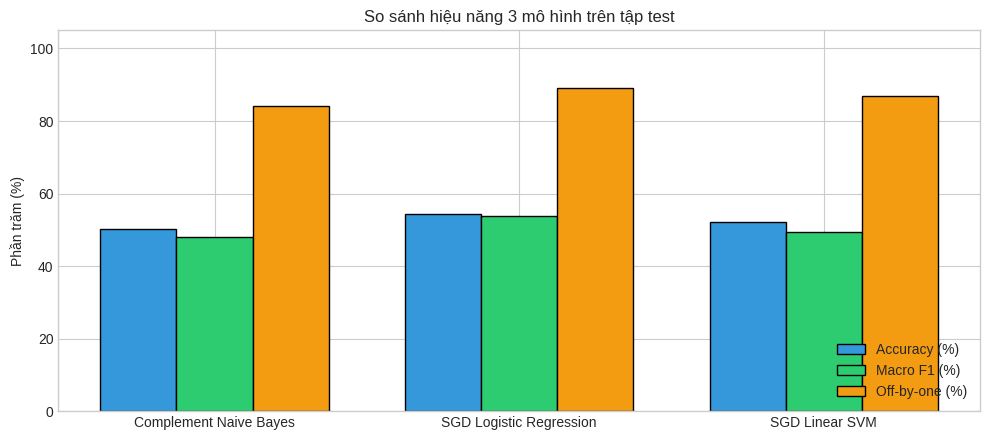

Mô hình tốt nhất theo Macro F1: SGD Logistic Regression


In [16]:
preds, rows = {}, []
for name, model in final_models.items():
    t0 = time.time()
    pred = model.predict(X_test)
    pt = time.time() - t0
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average='macro')
    preds[name] = pred
    rows.append({'Mô hình': name,
                 'Accuracy (%)': accuracy_score(y_test, pred) * 100,
                 'Precision (%)': p * 100, 'Recall (%)': r * 100, 'Macro F1 (%)': f1 * 100,
                 'Off-by-one (%)': np.mean(np.abs(y_test - pred) <= 1) * 100,
                 'MAE (sao)': np.mean(np.abs(y_test - pred)),
                 'Train (s)': train_times[name], 'Predict (s)': pt})
df_eval = pd.DataFrame(rows).round(3)
print('=== BẢNG SO SÁNH 3 MÔ HÌNH TRÊN TẬP TEST ===')
display(df_eval)

x = np.arange(len(df_eval)); w = 0.25
plt.figure(figsize=(10, 4.5))
plt.bar(x - w, df_eval['Accuracy (%)'],    w, label='Accuracy (%)',    color='#3498db', edgecolor='black')
plt.bar(x,     df_eval['Macro F1 (%)'],    w, label='Macro F1 (%)',    color='#2ecc71', edgecolor='black')
plt.bar(x + w, df_eval['Off-by-one (%)'],  w, label='Off-by-one (%)',  color='#f39c12', edgecolor='black')
plt.xticks(x, df_eval['Mô hình']); plt.ylabel('Phần trăm (%)'); plt.ylim(0, 105)
plt.title('So sánh hiệu năng 3 mô hình trên tập test'); plt.legend(loc='lower right')
plt.show()

best_name = df_eval.sort_values('Macro F1 (%)', ascending=False).iloc[0]['Mô hình']
print(f'Mô hình tốt nhất theo Macro F1: {best_name}')

=== CLASSIFICATION REPORT: SGD Logistic Regression ===
              precision    recall  f1-score   support

       1 sao     0.6251    0.6979    0.6595     19500
       2 sao     0.4848    0.4309    0.4563     19500
       3 sao     0.4792    0.4261    0.4510     19500
       4 sao     0.4886    0.4359    0.4607     19500
       5 sao     0.6042    0.7332    0.6625     19500

    accuracy                         0.5448     97500
   macro avg     0.5364    0.5448    0.5380     97500
weighted avg     0.5364    0.5448    0.5380     97500



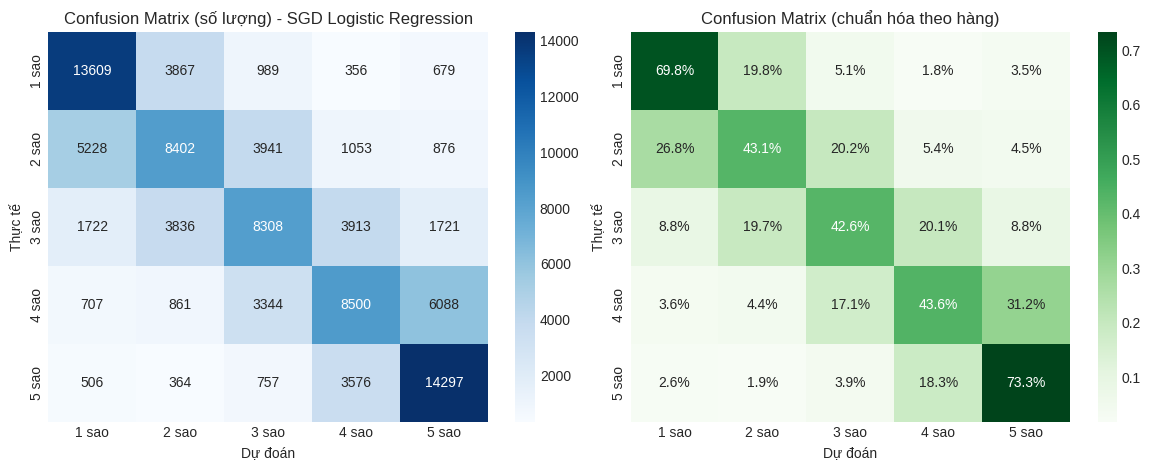

In [17]:
print(f'=== CLASSIFICATION REPORT: {best_name} ===')
print(classification_report(y_test, preds[best_name], target_names=[f'{i} sao' for i in range(1, 6)], digits=4))

cm = confusion_matrix(y_test, preds[best_name])
cm_norm = cm.astype(float) / cm.sum(axis=1)[:, None]
lab = [f'{i} sao' for i in range(1, 6)]
plt.figure(figsize=(12, 4.8))
plt.subplot(1, 2, 1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=lab, yticklabels=lab)
plt.title(f'Confusion Matrix (số lượng) - {best_name}'); plt.xlabel('Dự đoán'); plt.ylabel('Thực tế')
plt.subplot(1, 2, 2)
sns.heatmap(cm_norm, annot=True, fmt='.1%', cmap='Greens', xticklabels=lab, yticklabels=lab)
plt.title('Confusion Matrix (chuẩn hóa theo hàng)'); plt.xlabel('Dự đoán'); plt.ylabel('Thực tế')
plt.show()

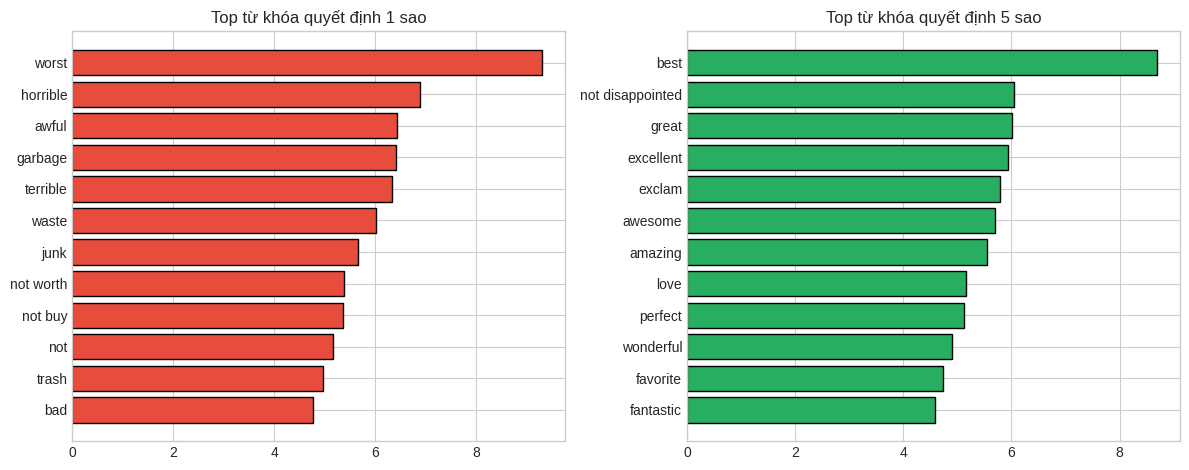

In [18]:
# Từ khóa quyết định của mô hình Logistic Regression (mô hình tuyến tính dễ diễn giải)
lr = final_models['SGD Logistic Regression']
coef = lr.coef_                      # hàng 0 ứng với 1 sao, hàng 4 ứng với 5 sao (lr.classes_ = [1..5])
top_n = 12
neg_i = coef[0].argsort()[-top_n:][::-1]
pos_i = coef[4].argsort()[-top_n:][::-1]

plt.figure(figsize=(12, 4.8))
plt.subplot(1, 2, 1)
plt.barh(vocab[neg_i][::-1], coef[0][neg_i][::-1], color='#e74c3c', edgecolor='black')
plt.title('Top từ khóa quyết định 1 sao')
plt.subplot(1, 2, 2)
plt.barh(vocab[pos_i][::-1], coef[4][pos_i][::-1], color='#27ae60', edgecolor='black')
plt.title('Top từ khóa quyết định 5 sao')
plt.show()

**Nhận xét:**

1. *Xếp hạng mô hình:*
- **SGD Logistic Regression** tốt nhất với accuracy 54,48%, macro F1 53,80%, off-by-one 89,14% và MAE 0,612 sao.
- Tiếp theo là **Linear SVM** (52,10% / 49,27% / 86,83% / 0,667)
- Cuối cùng là **Complement Naive Bayes** (50,26% / 47,99% / 84,26% / 0,738)..
2. *Confusion matrix:*
- Hai mức cực biên dễ nhất: **5 sao** (F1 = 0,6625, recall 73,3%) và **1 sao** (F1 = 0,6595, recall 69,8%). Ba mức giữa khó hơn nhiều với F1 chỉ khoảng 0,45–0,46, trong đó **3 sao khó nhất** (F1 = 0,4510).
- Phần lớn lỗi là nhầm sang mức **kề bên**: Nhầm lẫn lớn nhất là **4 sao bị đoán thành 5 sao (31,2%)**
3. *Từ khóa:* các từ có trọng số lớn nhất cho 1 sao là worst, horrible, awful, garbage, ...; cho 5 sao là best, not disappointed, great, excellent, awesome,..... Các từ này đều khớp với trực giác (từ chê và từ khen).

## 12. Demo dự đoán trực tiếp (input → output)

Hàm predict_sentiment nhận tiêu đề và nội dung review, làm sạch bằng đúng hàm clean_series đã dùng khi huấn luyện, rồi dùng mô hình Logistic Regression để trả về số sao dự đoán cùng xác suất của cả 5 mức.

In [19]:
labels_dict = {1: '1 sao (Rất tiêu cực / Thất vọng)', 2: '2 sao (Tiêu cực / Không hài lòng)',
               3: '3 sao (Trung lập / Bình thường)', 4: '4 sao (Tích cực / Hài lòng)',
               5: '5 sao (Xuất sắc / Tuyệt vời)'}

def predict_sentiment(title, review_text, model=None):
    if model is None:
        model = final_models['SGD Logistic Regression']
    vec = tfidf.transform(clean_series(pd.Series([f'{title} . {review_text}'])))
    probs = model.predict_proba(vec)[0]
    pred = int(model.classes_[probs.argmax()])
    print('-' * 70)
    print(f'Title   : {title}')
    print(f'Review  : {review_text}')
    print(f'Dự đoán : {labels_dict[pred]}  (xác suất {probs.max()*100:.1f}%)')
    print('Xác suất: ' + ' | '.join(f'{int(c)} sao: {p*100:4.1f}%' for c, p in zip(model.classes_, probs)))
    return pred

test_cases = [
    ('Terrible waste of money', 'Broke on the first day. Very bad quality and useless.'),
    ('Average product', 'It works fine, but nothing special. Delivery took longer than expected.'),
    ('Fantastic book!', 'One of the best books I have ever read. Highly recommend to everyone!'),
    ('Not good at all', 'I would not buy this again. It does not work as described.'),   # kiểm tra từ phủ định
]
for t, r in test_cases:
    predict_sentiment(t, r)

----------------------------------------------------------------------
Title   : Terrible waste of money
Review  : Broke on the first day. Very bad quality and useless.
Dự đoán : 1 sao (Rất tiêu cực / Thất vọng)  (xác suất 84.5%)
Xác suất: 1 sao: 84.5% | 2 sao: 15.2% | 3 sao:  0.3% | 4 sao:  0.0% | 5 sao:  0.0%
----------------------------------------------------------------------
Title   : Average product
Review  : It works fine, but nothing special. Delivery took longer than expected.
Dự đoán : 3 sao (Trung lập / Bình thường)  (xác suất 69.7%)
Xác suất: 1 sao:  1.0% | 2 sao: 15.1% | 3 sao: 69.7% | 4 sao: 12.4% | 5 sao:  1.8%
----------------------------------------------------------------------
Title   : Fantastic book!
Review  : One of the best books I have ever read. Highly recommend to everyone!
Dự đoán : 5 sao (Xuất sắc / Tuyệt vời)  (xác suất 95.4%)
Xác suất: 1 sao:  0.8% | 2 sao:  0.3% | 3 sao:  0.2% | 4 sao:  3.3% | 5 sao: 95.4%
------------------------------------------------

Test với my_title và my_review

In [20]:
my_title  = 'Totally exceeded my expectations!'
my_review = 'Fast shipping, high quality material, and works perfectly. Definitely worth buying!'
predict_sentiment(my_title, my_review);

----------------------------------------------------------------------
Title   : Totally exceeded my expectations!
Review  : Fast shipping, high quality material, and works perfectly. Definitely worth buying!
Dự đoán : 5 sao (Xuất sắc / Tuyệt vời)  (xác suất 65.7%)
Xác suất: 1 sao:  1.3% | 2 sao:  1.4% | 3 sao:  4.0% | 4 sao: 27.6% | 5 sao: 65.7%


## 13. Ứng dụng thực tế: tổng hợp bình luận của một sản phẩm và chẩn đoán vấn đề



In [21]:
import joblib
MODEL_PATH = 'amazon_sentiment_model.joblib'
joblib.dump({'tfidf': tfidf, 'model': final_models['SGD Logistic Regression']}, MODEL_PATH)
print(f'Đã lưu mô hình: {MODEL_PATH} ({os.path.getsize(MODEL_PATH)/1e6:.1f} MB)')

Đã lưu mô hình: amazon_sentiment_model.joblib (4.8 MB)


### 13.1 Cấu hình quy tắc và từ điển khía cạnh

Các ngưỡng đặt ở một chỗ để dễ chỉnh. **Từ điển khía cạnh** là bảng từ khóa tiếng Anh viết tay (không học từ dữ liệu), mỗi khía cạnh gồm một biểu thức chính quy.

In [22]:
import textwrap

# ---------------- NGƯỠNG KẾT LUẬN ----------------
GOOD_THRESHOLD      = 3.0   # sao trung bình > ngưỡng này thì sản phẩm được coi là tốt
VERY_GOOD_THRESHOLD = 4.0   # từ mức này trở lên: "rất tốt"
VERY_BAD_THRESHOLD  = 2.0   # từ mức này trở xuống: "rất không tốt"
MIN_REVIEWS         = 10    # ít bình luận hơn mức này thì cảnh báo kết luận kém tin cậy
N_BOOT              = 1000  # số lần lấy mẫu lại để tính khoảng tin cậy

# ---------------- NGƯỠNG CHẨN ĐOÁN VẤN ĐỀ ----------------
NEG_SENT_PROB   = 0.5   # câu được coi là phàn nàn nếu P(1 sao hoặc 2 sao) >= ngưỡng này
MIN_ISSUE_COUNT = 2     # một khía cạnh phải có ít nhất ngần này bình luận tiêu cực nhắc tới
MIN_ISSUE_SHARE = 0.10  # và chiếm ít nhất 10% số bình luận tiêu cực
MAX_ISSUES      = 5     # in tối đa ngần này vấn đề

# ---------------- TỪ ĐIỂN KHÍA CẠNH ----------------
ASPECTS = {
    'Giao hàng & đóng gói':
        r'\b(?:ship\w*|deliver\w*|arriv\w*|packag\w*|packing|courier|postal|late|took (?:forever|too long|weeks)|never came)\b',
    'Chất lượng sản phẩm':
        r'\b(?:quality|cheap\w*|flimsy|poorly made|junk|garbage|crap|trash|shoddy|defective|material\w*)\b',
    'Độ bền / hỏng hóc':
        r'\b(?:broke\w*|break\w*|stopped working|stop working|quit working|died|dead|malfunction\w*|fell apart|falls apart|fall apart|wore out|worn out|ripped|tore|cracked|lasted|lasts|burn\w* out|failed|failure)\b',
    'Hoạt động kém / không dùng được':
        r'\b(?:(?:not|never|barely|hardly) (?:work|works|worked|working)|useless|worthless|does nothing|no good|poor performance)\b',
    'Giá cả / không đáng tiền':
        r'\b(?:price\w*|expensive|overpriced|over priced|money|worth|cost\w*|rip ?off)\b',
    'Không đúng mô tả':
        r'\b(?:as described|as advertised|as pictured|as shown|as expected|not what (?:i|we) (?:expected|ordered)|misleading|false advertising|nothing like|different from|photo\w*|picture\w*|description)\b',
    'Kích cỡ / vừa vặn':
        r'\b(?:size\w*|fit|fits|fitted|fitting|too (?:small|big|large|tight|loose|short|long)|runs (?:small|large|big))\b',
    'Dịch vụ khách hàng & đổi trả':
        r'\b(?:customer (?:service|support)|seller|refund\w*|return\w*|exchang\w*|warranty|replacement|vendor)\b',
    'Nội dung / trải nghiệm (sách, phim, nhạc)':
        r'\b(?:boring|dull|plot|story|characters?|writing|written|acting|actors?|ending|lyrics|songs?|predictable)\b',
}

# Gợi ý hướng cải thiện (chung, để chủ sản phẩm tham khảo)
ACTIONS = {
    'Giao hàng & đóng gói': 'Xem lại đối tác vận chuyển, thời gian giao hàng và bao bì chống va đập.',
    'Chất lượng sản phẩm': 'Kiểm tra lại nhà cung cấp, vật liệu và quy trình kiểm tra chất lượng trước khi xuất kho.',
    'Độ bền / hỏng hóc': 'Kiểm tra tỉ lệ lỗi theo lô hàng, tăng kiểm tra độ bền; cân nhắc chính sách bảo hành.',
    'Hoạt động kém / không dùng được': 'Kiểm tra tính năng cốt lõi, tương thích và hướng dẫn sử dụng; kiểm thử trước khi bán.',
    'Giá cả / không đáng tiền': 'Xem lại mức giá so với chất lượng và đối thủ, hoặc làm rõ giá trị mang lại trong phần mô tả.',
    'Không đúng mô tả': 'Cập nhật ảnh, thông số và mô tả đúng với sản phẩm thật để khách không kỳ vọng sai.',
    'Kích cỡ / vừa vặn': 'Bổ sung bảng kích cỡ chi tiết, số đo thực tế và hướng dẫn chọn size.',
    'Dịch vụ khách hàng & đổi trả': 'Rút ngắn thời gian phản hồi, đơn giản hóa quy trình đổi trả và hoàn tiền.',
    'Nội dung / trải nghiệm (sách, phim, nhạc)': 'Rà soát nội dung hoặc phân khúc khách hàng mục tiêu; làm rõ thể loại trong phần giới thiệu.',
}
print('Đã nạp cấu hình:', len(ASPECTS), 'khía cạnh.')

Đã nạp cấu hình: 9 khía cạnh.


### 13.2 Các hàm xử lý


In [23]:
APP_MODEL = final_models['SGD Logistic Regression']   # mô hình có predict_proba, dùng cho ứng dụng

def predict_stars(texts):
    X = tfidf.transform(clean_series(pd.Series(list(texts), dtype=object)))
    P = APP_MODEL.predict_proba(X)
    return APP_MODEL.classes_[P.argmax(axis=1)].astype(int), P

_SPLIT = re.compile(r'(?<=[.!?])\s+|\\n|<br\s*/?>|\n')
def split_sentences(text, min_words=2):
    # Chỉ đếm từ chữ cái (bỏ dấu câu rời), giữ cả câu ngắn như "Poor quality." vì lời chê thường rất ngắn
    parts = [p.strip() for p in _SPLIT.split(text) if p and p.strip()]
    return [p for p in parts if len(re.findall(r"[A-Za-z']+", p)) >= min_words]

def detect_complaints(texts):
    # Trả về bảng các câu phàn nàn: rid (số thứ tự bình luận), sentence, aspect, p_neg
    cols = ['rid', 'sentence', 'aspect', 'p_neg']
    rows = [(rid, s) for rid, t in enumerate(texts) for s in split_sentences(t)]
    if not rows:
        return pd.DataFrame(columns=cols)
    sdf = pd.DataFrame(rows, columns=['rid', 'sentence'])
    sdf['clean'] = clean_series(sdf['sentence'])
    out = []
    for asp, pat in ASPECTS.items():
        hit = sdf[sdf['clean'].str.contains(pat, regex=True)]
        if len(hit):
            P = APP_MODEL.predict_proba(tfidf.transform(hit['clean']))
            h = hit[['rid', 'sentence']].copy()
            h['aspect'] = asp
            h['p_neg'] = P[:, 0] + P[:, 1]          # xác suất câu thuộc 1 sao hoặc 2 sao
            out.append(h)
    if not out:
        return pd.DataFrame(columns=cols)
    res = pd.concat(out, ignore_index=True)
    return res[res['p_neg'] >= NEG_SENT_PROB]

def bootstrap_ci(x, n_boot=N_BOOT, seed=0):
    rng_b = np.random.default_rng(seed)
    means = np.array([x[rng_b.integers(0, len(x), len(x))].mean() for _ in range(n_boot)])
    return np.percentile(means, [2.5, 97.5])

def analyze_product(texts, name='Sản phẩm', verbose=True, plot=True):
    texts = [t for t in texts if isinstance(t, str) and t.strip()]
    n = len(texts)
    if n == 0:
        raise ValueError('Không có bình luận nào để phân tích.')

    # ---- Bước 1-2: dự đoán và tổng hợp ----
    stars, _ = predict_stars(texts)
    avg = float(stars.mean())
    lo, hi = bootstrap_ci(stars)
    pos, neu, neg = (stars >= 4).mean() * 100, (stars == 3).mean() * 100, (stars <= 2).mean() * 100

    # ---- Bước 3: kết luận ----
    good = avg > GOOD_THRESHOLD
    if good:
        verdict = 'RẤT TỐT (TÍCH CỰC)' if avg >= VERY_GOOD_THRESHOLD else 'TỐT (TÍCH CỰC)'
    else:
        verdict = 'RẤT KHÔNG TỐT' if avg <= VERY_BAD_THRESHOLD else 'KHÔNG TỐT'
    borderline = lo <= GOOD_THRESHOLD <= hi

    # ---- Bước 4: chẩn đoán vấn đề (chỉ khi không tốt) ----
    issues, n_neg, unexplained = [], int((stars <= 2).sum()), None
    if not good and n_neg > 0:
        neg_texts = [texts[i] for i in np.where(stars <= 2)[0]]
        comp = detect_complaints(neg_texts)
        for asp, g in comp.groupby('aspect'):
            cnt = g['rid'].nunique()
            if cnt >= MIN_ISSUE_COUNT and cnt / n_neg >= MIN_ISSUE_SHARE:
                ex = g.sort_values('p_neg', ascending=False)['sentence'].drop_duplicates().head(2).tolist()
                issues.append({'aspect': asp, 'count': cnt, 'share': cnt / n_neg, 'examples': ex})
        issues = sorted(issues, key=lambda d: d['count'], reverse=True)[:MAX_ISSUES]
        unexplained = 1 - (comp['rid'].nunique() / n_neg if len(comp) else 0)

    result = {'name': name, 'n': n, 'avg': avg, 'ci': (lo, hi), 'pct_pos': pos, 'pct_neu': neu, 'pct_neg': neg,
              'good': good, 'verdict': verdict, 'borderline': borderline, 'n_neg': n_neg,
              'issues': issues, 'unexplained': unexplained}

    # ---- Báo cáo ----
    if verbose:
        line = '=' * 76
        print(line); print(f'SẢN PHẨM: {name}  ({n} bình luận)'); print(line)
        if n < MIN_REVIEWS:
            print(f'(!) Chỉ có {n} bình luận (ít hơn {MIN_REVIEWS}), kết luận kém tin cậy.')
        if good:
            print(f'KẾT LUẬN: [OK] SẢN PHẨM ĐANG {verdict}')
            print(f'(Sao trung bình dự đoán: {avg:.2f}/5)')
        else:
            print(f'KẾT LUẬN: [X] SẢN PHẨM {verdict}')
            print(f'Sao trung bình: {avg:.2f}/5   (khoảng tin cậy 95%: {lo:.2f} - {hi:.2f})')
            print(f'Phân bố: {pos:.0f}% tích cực (4-5 sao) | {neu:.0f}% trung lập (3 sao) | {neg:.0f}% tiêu cực (1-2 sao)')
            if borderline:
                print(f'(!) Khoảng tin cậy chứa ngưỡng {GOOD_THRESHOLD}: kết luận đang sát ranh giới, nên theo dõi thêm.')
            print('\nSản phẩm không tốt về:')
            if issues:
                for k, it in enumerate(issues, 1):
                    print(f"  {k}. {it['aspect']}: {it['count']}/{n_neg} bình luận tiêu cực ({it['share']*100:.0f}%)")
                    for ex in it['examples']:
                        print('       - "' + textwrap.shorten(ex, 170, placeholder='...') + '"')
                    print(f"       => Gợi ý: {ACTIONS[it['aspect']]}")
                print(f'\nGhi chú: một bình luận có thể nhắc nhiều khía cạnh nên tỉ lệ không cộng lại thành 100%. '
                      f'{unexplained*100:.0f}% bình luận tiêu cực không nhắc khía cạnh nào trong từ điển.')
            else:
                print('  (Chưa xác định được vấn đề cụ thể bằng từ điển khía cạnh. Hãy đọc trực tiếp các bình luận 1-2 sao.)')

        if plot and issues:
            plt.figure(figsize=(8, 0.6 * len(issues) + 1.5))
            names = [it['aspect'] for it in issues][::-1]
            vals = [it['share'] * 100 for it in issues][::-1]
            plt.barh(names, vals, color='#e74c3c', edgecolor='black')
            for i, v in enumerate(vals):
                plt.text(v + 0.5, i, f'{v:.0f}%', va='center')
            plt.xlim(0, max(vals) * 1.2)
            plt.title(f'Vấn đề chính của: {name}')
            plt.xlabel('% bình luận tiêu cực nhắc tới')
            plt.show()
    return result

def summarize_products(products, true_avg=None):
    rows = []
    for pname, ptexts in products.items():
        r = analyze_product(ptexts, pname, verbose=False, plot=False)
        row = {'Sản phẩm': pname, 'Số bình luận': r['n'], 'Sao TB (dự đoán)': round(r['avg'], 2),
               '% tích cực': round(r['pct_pos']), '% tiêu cực': round(r['pct_neg']), 'Kết luận': r['verdict'],
               'Vấn đề chính': ('; '.join(f"{i['aspect']} ({i['share']*100:.0f}%)" for i in r['issues'][:3])
                                or ('—' if r['good'] else 'chưa xác định'))}
        if true_avg is not None:
            row['Sao TB thật (đối chiếu)'] = round(float(true_avg[pname]), 2)
        rows.append(row)
    return pd.DataFrame(rows)

def analyze_dataframe(df, product_col='product', text_col='review'):
    # df có một cột mã/tên sản phẩm và một cột bình luận
    return summarize_products({n: g[text_col].tolist() for n, g in df.groupby(product_col)})

print('Đã định nghĩa xong các hàm.')

Đã định nghĩa xong các hàm.


### 13.3 Demo trên các sản phẩm mô phỏng

- Bộ dữ liệu này **không có mã sản phẩm**, nên không thể lấy "tất cả bình luận của một sản phẩm thật". Để demo, ta **ghép** các sản phẩm giả từ tập test (mỗi sản phẩm gồm khoảng 50 bình luận):

- **A:** phần lớn bình luận 4–5 sao.
- **B:** nhiều bình luận 1–2 sao có nhắc tới giao hàng.
- **C:** nhiều bình luận 1–2 sao nhắc tới chất lượng và độ bền.
- **D:** nhiều bình luận 1–2 sao nhắc tới giá và dịch vụ khách hàng.

In [24]:
# Dựng sản phẩm mô phỏng từ tập test
has_aspect = {a: df_test['clean'].str.contains(p, regex=True).values for a, p in ASPECTS.items()}

def build_product(spec, seed):
    rng_p = np.random.default_rng(seed)
    picked = []
    for stars_in, n_pick, aspect in spec:
        mask = np.isin(y_test, stars_in)
        if aspect:
            mask &= has_aspect[aspect]
        cand = np.where(mask)[0]
        picked.extend(rng_p.choice(cand, size=min(n_pick, len(cand)), replace=False))
    picked = np.array(picked)
    rng_p.shuffle(picked)
    return picked

DEMO_SPECS = {
    'Sản phẩm A (mô phỏng: được khen)':
        [([4, 5], 42, None), ([3], 5, None), ([1, 2], 3, None)],
    'Sản phẩm B (mô phỏng: bị chê giao hàng)':
        [([1, 2], 22, 'Giao hàng & đóng gói'), ([1, 2], 8, None), ([3], 8, None), ([4, 5], 12, None)],
    'Sản phẩm C (mô phỏng: bị chê chất lượng, độ bền)':
        [([1, 2], 14, 'Độ bền / hỏng hóc'), ([1, 2], 10, 'Chất lượng sản phẩm'), ([1, 2], 6, None), ([3], 8, None), ([4, 5], 12, None)],
    'Sản phẩm D (mô phỏng: bị chê giá và dịch vụ)':
        [([1, 2], 12, 'Giá cả / không đáng tiền'), ([1, 2], 12, 'Dịch vụ khách hàng & đổi trả'), ([1, 2], 6, None), ([3], 8, None), ([4, 5], 12, None)],
}
demo_products, demo_true_avg = {}, {}
for i, (pname, spec) in enumerate(DEMO_SPECS.items()):
    idx = build_product(spec, seed=100 + i)
    demo_products[pname] = df_test['full_raw'].iloc[idx].tolist()
    demo_true_avg[pname] = y_test[idx].mean()
print({k: len(v) for k, v in demo_products.items()})

{'Sản phẩm A (mô phỏng: được khen)': 50, 'Sản phẩm B (mô phỏng: bị chê giao hàng)': 50, 'Sản phẩm C (mô phỏng: bị chê chất lượng, độ bền)': 50, 'Sản phẩm D (mô phỏng: bị chê giá và dịch vụ)': 50}


In [25]:
# Sản phẩm TỐT:
r_A = analyze_product(demo_products['Sản phẩm A (mô phỏng: được khen)'], 'Sản phẩm A (mô phỏng: được khen)')

SẢN PHẨM: Sản phẩm A (mô phỏng: được khen)  (50 bình luận)
KẾT LUẬN: [OK] SẢN PHẨM ĐANG RẤT TỐT (TÍCH CỰC)
(Sao trung bình dự đoán: 4.06/5)


SẢN PHẨM: Sản phẩm B (mô phỏng: bị chê giao hàng)  (50 bình luận)
KẾT LUẬN: [X] SẢN PHẨM KHÔNG TỐT
Sao trung bình: 2.60/5   (khoảng tin cậy 95%: 2.22 - 3.02)
Phân bố: 30% tích cực (4-5 sao) | 16% trung lập (3 sao) | 54% tiêu cực (1-2 sao)
(!) Khoảng tin cậy chứa ngưỡng 3.0: kết luận đang sát ranh giới, nên theo dõi thêm.

Sản phẩm không tốt về:
  1. Giá cả / không đáng tiền: 9/27 bình luận tiêu cực (33%)
       - "don't waste your money ."
       - "Total waste of money ."
       => Gợi ý: Xem lại mức giá so với chất lượng và đối thủ, hoặc làm rõ giá trị mang lại trong phần mô tả.
  2. Giao hàng & đóng gói: 8/27 bình luận tiêu cực (30%)
       - "Without handles, this bag is practically impossible to move.Rubbermaid could fix this problem by having the handle fabric wrap all the way under the bag.Don't buy this..."
       - "The plastic ring at the base that attaches to the pump was deformed and would not mount on the pump properly, when i slid the pump lock over the mount it started t

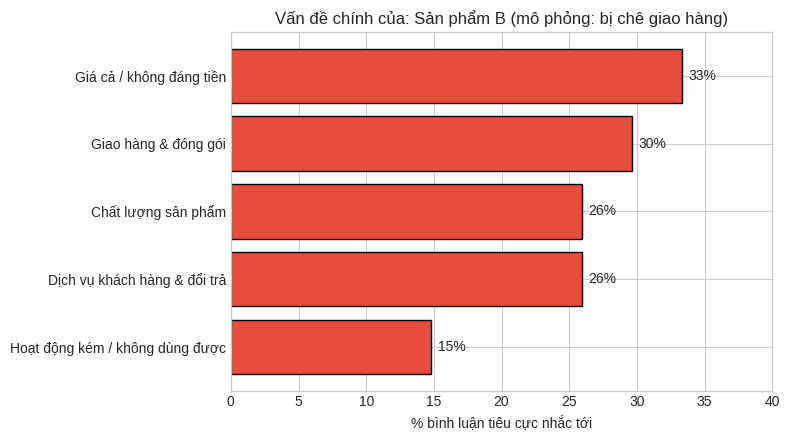

In [26]:
# Sản phẩm KHÔNG TỐT: in sao trung bình, phân bố, vấn đề chính và gợi ý cải thiện
r_B = analyze_product(demo_products['Sản phẩm B (mô phỏng: bị chê giao hàng)'], 'Sản phẩm B (mô phỏng: bị chê giao hàng)')

SẢN PHẨM: Sản phẩm C (mô phỏng: bị chê chất lượng, độ bền)  (50 bình luận)
KẾT LUẬN: [X] SẢN PHẨM KHÔNG TỐT
Sao trung bình: 2.58/5   (khoảng tin cậy 95%: 2.18 - 2.96)
Phân bố: 30% tích cực (4-5 sao) | 12% trung lập (3 sao) | 58% tiêu cực (1-2 sao)

Sản phẩm không tốt về:
  1. Chất lượng sản phẩm: 10/29 bình luận tiêu cực (34%)
       - "This is the second one that I bought.JUNK"
       - "The director of the piece of cinematic [garbage] clearly is of bad stock."
       => Gợi ý: Kiểm tra lại nhà cung cấp, vật liệu và quy trình kiểm tra chất lượng trước khi xuất kho.
  2. Độ bền / hỏng hóc: 10/29 bình luận tiêu cực (34%)
       - "Lying Sophistry, Defective Casuistry, Same'ol Failed Apologetics ."
       - "There was potential here, but the authors failure to get off the ground make this book a "pass it by"."
       => Gợi ý: Kiểm tra tỉ lệ lỗi theo lô hàng, tăng kiểm tra độ bền; cân nhắc chính sách bảo hành.
  3. Nội dung / trải nghiệm (sách, phim, nhạc): 6/29 bình luận tiêu cực (21%)


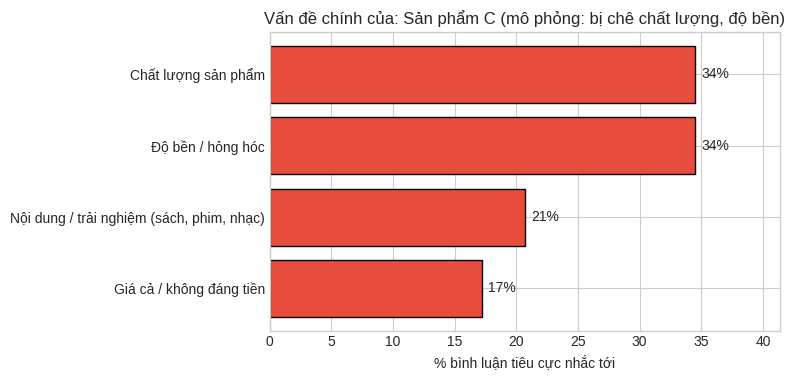

In [27]:
r_C = analyze_product(demo_products['Sản phẩm C (mô phỏng: bị chê chất lượng, độ bền)'], 'Sản phẩm C (mô phỏng: bị chê chất lượng, độ bền)')

In [28]:
# Bảng tổng hợp nhiều sản phẩm (dành cho chủ cửa hàng có nhiều mặt hàng)
display(summarize_products(demo_products, true_avg=demo_true_avg))

,Sản phẩm,Số bình luận,Sao TB (dự đoán),% tích cực,% tiêu cực,Kết luận,Vấn đề chính,Sao TB thật (đối chiếu)
0,Sản phẩm A (mô phỏng: được khen),50,4.06,82,10,RẤT TỐT (TÍCH CỰC),—,4.04
1,Sản phẩm B (mô phỏng: bị chê giao hàng),50,2.60,30,54,KHÔNG TỐT,Giá cả / không đáng tiền (33%); Giao hàng & đóng gói (30%); Chất lượng sản phẩm (26%),2.52
2,"Sản phẩm C (mô phỏng: bị chê chất lượng, độ bền)",50,2.58,30,58,KHÔNG TỐT,"Chất lượng sản phẩm (34%); Độ bền / hỏng hóc (34%); Nội dung / trải nghiệm (sách, phim, nhạc) (21%)",2.40
3,Sản phẩm D (mô phỏng: bị chê giá và dịch vụ),50,2.48,30,54,KHÔNG TỐT,Dịch vụ khách hàng & đổi trả (44%); Giá cả / không đáng tiền (41%); Chất lượng sản phẩm (30%),2.48


### 13.4 Dùng cho bình luận riêng

SẢN PHẨM: Tai nghe không dây XYZ  (12 bình luận)
KẾT LUẬN: [X] SẢN PHẨM KHÔNG TỐT
Sao trung bình: 2.33/5   (khoảng tin cậy 95%: 1.67 - 3.17)
Phân bố: 25% tích cực (4-5 sao) | 8% trung lập (3 sao) | 67% tiêu cực (1-2 sao)
(!) Khoảng tin cậy chứa ngưỡng 3.0: kết luận đang sát ranh giới, nên theo dõi thêm.

Sản phẩm không tốt về:
  1. Dịch vụ khách hàng & đổi trả: 3/8 bình luận tiêu cực (38%)
       - "Returned it."
       - "I want a refund."
       => Gợi ý: Rút ngắn thời gian phản hồi, đơn giản hóa quy trình đổi trả và hoàn tiền.
  2. Chất lượng sản phẩm: 2/8 bình luận tiêu cực (25%)
       - "Terrible quality, broke in a few days."
       - "Sound quality is poor and it feels cheap."
       => Gợi ý: Kiểm tra lại nhà cung cấp, vật liệu và quy trình kiểm tra chất lượng trước khi xuất kho.
  3. Giao hàng & đóng gói: 2/8 bình luận tiêu cực (25%)
       - "Very disappointed with the shipping."
       - "The package was damaged when it arrived."
       => Gợi ý: Xem lại đối tác vận chuyển,

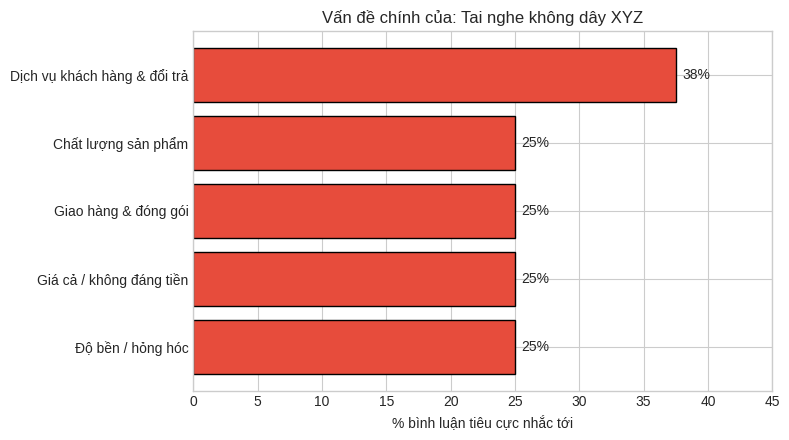

In [29]:
my_product_name = 'Tai nghe không dây XYZ'
my_reviews = [
    "Arrived two weeks late and the box was crushed. Very disappointed with the shipping.",
    "The package was damaged when it arrived. Delivery took forever.",
    "Sound quality is poor and it feels cheap. Not worth the money.",
    "Stopped working after one week. Customer service never replied to my emails.",
    "Terrible quality, broke in a few days. I want a refund.",
    "Good sound for the price, but the battery is bad.",
    "Shipping was slow, the product itself is okay though.",
    "Waste of money. It does not work with my phone.",
    "Great headphones, fast delivery, very happy!",
    "Not as described. The photos look much better than the real thing.",
    "Returned it. The seller did not answer and refused to refund me.",
    "Works fine, comfortable to wear, decent price.",
]
r_my = analyze_product(my_reviews, my_product_name)

### 13.5 Kiểm chứng độ tin cậy của ứng dụng

Một công cụ ứng dụng chỉ đáng tin nếu ta **đo được** nó đúng đến đâu. Có hai câu hỏi cần kiểm tra.

**(a) Kết luận ở mức sản phẩm có đúng không?**

**(b) Từ điển khía cạnh có phân biệt được lời chê và lời khen không?**

Số sản phẩm giả: 500 (mỗi sản phẩm 50 bình luận)
Sai số tuyệt đối trung bình của sao TB (MAE): 0.178 sao
Độ lệch trung bình (dự đoán - thật): +0.046 sao
Hệ số tương quan giữa sao TB thật và dự đoán: 0.978
Kết luận tốt/không tốt đúng: 95.4% (tất cả sản phẩm)
Kết luận tốt/không tốt đúng: 99.7% (chỉ tính 292 sản phẩm cách ngưỡng 3.0 ít nhất 0,5 sao)


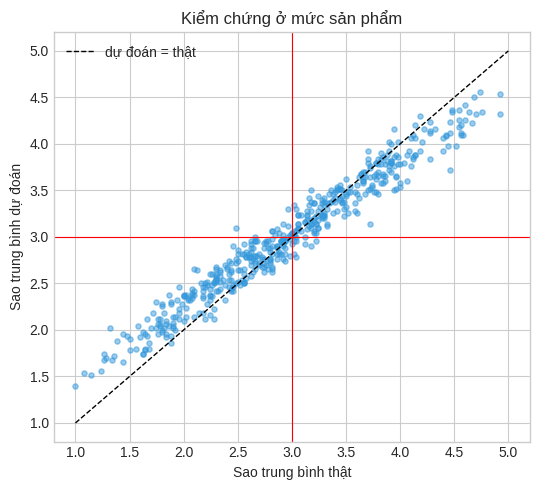

In [30]:
# (a) Kiểm chứng ở mức sản phẩm: sao TB thật vs sao TB dự đoán
N_SIM, N_PER = 500, 50
rng_v = np.random.default_rng(7)
pred_lr = preds['SGD Logistic Regression']
by_star = {k: np.where(y_test == k)[0] for k in range(1, 6)}

rows = []
for _ in range(N_SIM):
    w = rng_v.dirichlet(np.ones(5) * 0.5)               # cơ cấu sao ngẫu nhiên, trải rộng từ rất tệ đến rất tốt
    counts = rng_v.multinomial(N_PER, w)
    idx = np.concatenate([rng_v.choice(by_star[k], c, replace=False) for k, c in zip(range(1, 6), counts)])
    rows.append({'true_avg': y_test[idx].mean(), 'pred_avg': pred_lr[idx].mean()})
sim = pd.DataFrame(rows)
sim['err'] = sim['pred_avg'] - sim['true_avg']
sim['true_good'] = sim['true_avg'] > GOOD_THRESHOLD
sim['pred_good'] = sim['pred_avg'] > GOOD_THRESHOLD
clear = sim[(sim['true_avg'] - GOOD_THRESHOLD).abs() >= 0.5]    # bỏ các sản phẩm sát ranh giới

print(f'Số sản phẩm giả: {N_SIM} (mỗi sản phẩm {N_PER} bình luận)')
print(f'Sai số tuyệt đối trung bình của sao TB (MAE): {sim["err"].abs().mean():.3f} sao')
print(f'Độ lệch trung bình (dự đoán - thật): {sim["err"].mean():+.3f} sao')
print(f'Hệ số tương quan giữa sao TB thật và dự đoán: {np.corrcoef(sim["true_avg"], sim["pred_avg"])[0, 1]:.3f}')
print(f'Kết luận tốt/không tốt đúng: {(sim["true_good"] == sim["pred_good"]).mean()*100:.1f}% (tất cả sản phẩm)')
print(f'Kết luận tốt/không tốt đúng: {(clear["true_good"] == clear["pred_good"]).mean()*100:.1f}% '
      f'(chỉ tính {len(clear)} sản phẩm cách ngưỡng {GOOD_THRESHOLD} ít nhất 0,5 sao)')

plt.figure(figsize=(5.5, 5))
plt.scatter(sim['true_avg'], sim['pred_avg'], s=14, alpha=0.5, color='#3498db')
plt.plot([1, 5], [1, 5], 'k--', lw=1, label='dự đoán = thật')
plt.axhline(GOOD_THRESHOLD, color='r', lw=0.8); plt.axvline(GOOD_THRESHOLD, color='r', lw=0.8)
plt.xlabel('Sao trung bình thật'); plt.ylabel('Sao trung bình dự đoán')
plt.title('Kiểm chứng ở mức sản phẩm'); plt.legend()
plt.show()

In [31]:
# (b) Kiểm chứng từ điển khía cạnh: bình luận 1-2 sao có bị gắn cờ phàn nàn nhiều hơn bình luận 4-5 sao không?
N_VAL = 3000
neg_pool, pos_pool = np.where(y_test <= 2)[0], np.where(y_test >= 4)[0]
neg_s = rng.choice(neg_pool, min(N_VAL, len(neg_pool)), replace=False)
pos_s = rng.choice(pos_pool, min(N_VAL, len(pos_pool)), replace=False)

c_neg = detect_complaints(df_test['full_raw'].iloc[neg_s].tolist())
c_pos = detect_complaints(df_test['full_raw'].iloc[pos_s].tolist())

tab = []
for asp in ASPECTS:
    a = c_neg[c_neg['aspect'] == asp]['rid'].nunique() / len(neg_s) * 100
    b = c_pos[c_pos['aspect'] == asp]['rid'].nunique() / len(pos_s) * 100
    if b >= 0.5:
        ratio = round(a / b, 1)
    else:                                                     # nhóm 4-5 sao gần như không có: không chia
        ratio = 'chỉ có ở 1-2 sao' if a >= 0.5 else '—'
    tab.append({'Khía cạnh': asp, '% review 1-2 sao bị gắn cờ': round(a, 1),
                '% review 4-5 sao bị gắn cờ': round(b, 1), 'Tỉ lệ (lần)': ratio})
df_aspect_val = pd.DataFrame(tab).sort_values('% review 1-2 sao bị gắn cờ', ascending=False).reset_index(drop=True)
display(df_aspect_val)
print('Tỉ lệ lớn hơn 1: khía cạnh gắn với lời chê nhiều hơn lời khen. Tỉ lệ gần 1 hoặc thấp hơn: từ khóa chưa phân biệt được khen và chê.')

,Khía cạnh,% review 1-2 sao bị gắn cờ,% review 4-5 sao bị gắn cờ,Tỉ lệ (lần)
0,"Nội dung / trải nghiệm (sách, phim, nhạc)",22.2,3.7,6.0
1,Giá cả / không đáng tiền,16.5,1.5,10.7
2,Chất lượng sản phẩm,12.4,1.7,7.4
3,Dịch vụ khách hàng & đổi trả,7.6,0.9,8.2
4,Độ bền / hỏng hóc,6.9,1.0,6.6
5,Hoạt động kém / không dùng được,5.7,0.5,chỉ có ở 1-2 sao
6,Không đúng mô tả,4.6,1.1,4.3
7,Giao hàng & đóng gói,3.1,0.5,5.8
8,Kích cỡ / vừa vặn,2.6,0.3,chỉ có ở 1-2 sao


Tỉ lệ lớn hơn 1: khía cạnh gắn với lời chê nhiều hơn lời khen. Tỉ lệ gần 1 hoặc thấp hơn: từ khóa chưa phân biệt được khen và chê.


### 13.6 Hạn chế của phần ứng dụng


## 14. Kết luận



In [32]:
best = df_eval.sort_values('Macro F1 (%)', ascending=False).iloc[0]
per_class_f1 = f1_score(y_test, preds[best_name], average=None)
off = cm_norm.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
c_lo, c_hi = df_cluster.iloc[0], df_cluster.iloc[-1]

print('=' * 78)
print('TỔNG HỢP KẾT QUẢ')
print('=' * 78)
print(f'1. Dữ liệu: {N_TRAIN_FULL:,} train / {N_TEST_FULL:,} test; dùng {len(df_train):,} review train và {len(df_test):,} review test.')
print(f'2. Mô hình tốt nhất: {best_name} - Accuracy {best["Accuracy (%)"]:.2f}%, Macro F1 {best["Macro F1 (%)"]:.2f}%, '
      f'Off-by-one {best["Off-by-one (%)"]:.2f}%, MAE {best["MAE (sao)"]:.3f} sao (mức đoán ngẫu nhiên khoảng 20%).')
print(f'3. Nhãn dễ nhất: {per_class_f1.argmax()+1} sao (F1 = {per_class_f1.max():.3f}); khó nhất: {per_class_f1.argmin()+1} sao (F1 = {per_class_f1.min():.3f}).')
print(f'4. Nhầm lẫn nhiều nhất: thực tế {i+1} sao bị đoán thành {j+1} sao ({off[i, j]*100:.1f}% số review {i+1} sao).')
print(f'5. Phân cụm (k = {best_k}): cụm tiêu cực nhất có số sao TB {c_lo["Số sao TB"]} (từ khóa: {c_lo["Từ khóa nổi bật"][:60]}...), '
      f'cụm tích cực nhất có số sao TB {c_hi["Số sao TB"]}.')
r1, r5 = top_rules(1, 3), top_rules(5, 3)
print(f'6. Luật kết hợp mạnh nhất cho 1 sao: {", ".join(r1.iloc[:, 0])}; cho 5 sao: {", ".join(r5.iloc[:, 0])}.')

if 'sim' in globals() and 'df_aspect_val' in globals():
    acc_all   = (sim['true_good'] == sim['pred_good']).mean() * 100
    acc_clear = (clear['true_good'] == clear['pred_good']).mean() * 100
    mae_prod  = sim['err'].abs().mean()
    top_asp = df_aspect_val.head(3)
    asp_txt = '; '.join(f"{r['Khía cạnh']} ({r['% review 1-2 sao bị gắn cờ']}% so với {r['% review 4-5 sao bị gắn cờ']}%)"
                        for _, r in top_asp.iterrows())
    print(f'7. Ứng dụng ở mức sản phẩm (kiểm tra trên {N_SIM} sản phẩm giả, mỗi sản phẩm {N_PER} bình luận): '
          f'sao TB dự đoán lệch trung bình {mae_prod:.2f} sao so với thật; kết luận tốt/không tốt đúng {acc_all:.1f}% '
          f'({acc_clear:.1f}% nếu chỉ tính sản phẩm cách ngưỡng {GOOD_THRESHOLD} ít nhất 0,5 sao).')
    print(f'   Từ điển khía cạnh gắn cờ nhiều nhất ở review 1-2 sao (so với review 4-5 sao): {asp_txt}.')

print('=' * 78)

TỔNG HỢP KẾT QUẢ
1. Dữ liệu: 3,000,000 train / 650,000 test; dùng 600,000 review train và 97,500 review test.
2. Mô hình tốt nhất: SGD Logistic Regression - Accuracy 54.48%, Macro F1 53.80%, Off-by-one 89.14%, MAE 0.612 sao (mức đoán ngẫu nhiên khoảng 20%).
3. Nhãn dễ nhất: 5 sao (F1 = 0.662); khó nhất: 3 sao (F1 = 0.451).
4. Nhầm lẫn nhiều nhất: thực tế 4 sao bị đoán thành 5 sao (31.2% số review 4 sao).
5. Phân cụm (k = 6): cụm tiêu cực nhất có số sao TB 2.82 (từ khóa: not, good, like, did, great, product, just, dvd...), cụm tích cực nhất có số sao TB 3.28.
6. Luật kết hợp mạnh nhất cho 1 sao: zero stars, worst movies, piece junk; cho 5 sao: excellent exclam, fantastic exclam, exclam highly.
7. Ứng dụng ở mức sản phẩm (kiểm tra trên 500 sản phẩm giả, mỗi sản phẩm 50 bình luận): sao TB dự đoán lệch trung bình 0.18 sao so với thật; kết luận tốt/không tốt đúng 95.4% (99.7% nếu chỉ tính sản phẩm cách ngưỡng 3.0 ít nhất 0,5 sao).
   Từ điển khía cạnh gắn cờ nhiều nhất ở review 1-2 sao (so 